All data should be shaped as 'lat': -90 to 90 and 'lon': 0 to 360 <br />
Extent of clip: latitude = slice(-45, 15), longitude = slice(270, 330)

In [1]:
Prec = 'ERA5'
Landuse_map = 'Mapbiomas'

In [2]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import numpy as np
from tqdm import tqdm
import pandas as pd
#from numpy import *
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cartopy as cart


/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [3]:
Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]
Stakeholder['x'] = Stakeholder.x.values%360

/tmp/user/1011/ipykernel_3431142/3478874843.py:1: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]


In [46]:
E_era5 = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_evaporation/ERA5_daily/era5_evaporation_daily_daysum_*_p25.nc').e[:,::-1].sel(time = slice('2008','2017'), latitude = slice(-39.25, 10.25), longitude = slice(280+1, 330+1))
E_era5 = E_era5[:,:-1,:-1]*(-1000)
E_era5 = E_era5.resample(time = '1Y').sum('time')
E_era5 = E_era5.mean(axis = 0)
E_era5 = E_era5.coarsen(latitude = 2, longitude = 2).mean()

P_era5 = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_precipitation/ERA5_daily/era5_precipitation_daily_daysum_*_p25.nc').tp[:,::-1].sel(time = slice('2008','2017'), latitude = slice(-39.25, 10.25), longitude = slice(280+1, 330+1))
P_era5 = P_era5[:,:-1,:-1]*(1000)
P_era5 = P_era5.resample(time = '1Y').sum('time')
P_era5 = P_era5.mean(axis = 0)
P_era5 = P_era5.coarsen(latitude = 2, longitude = 2).mean()

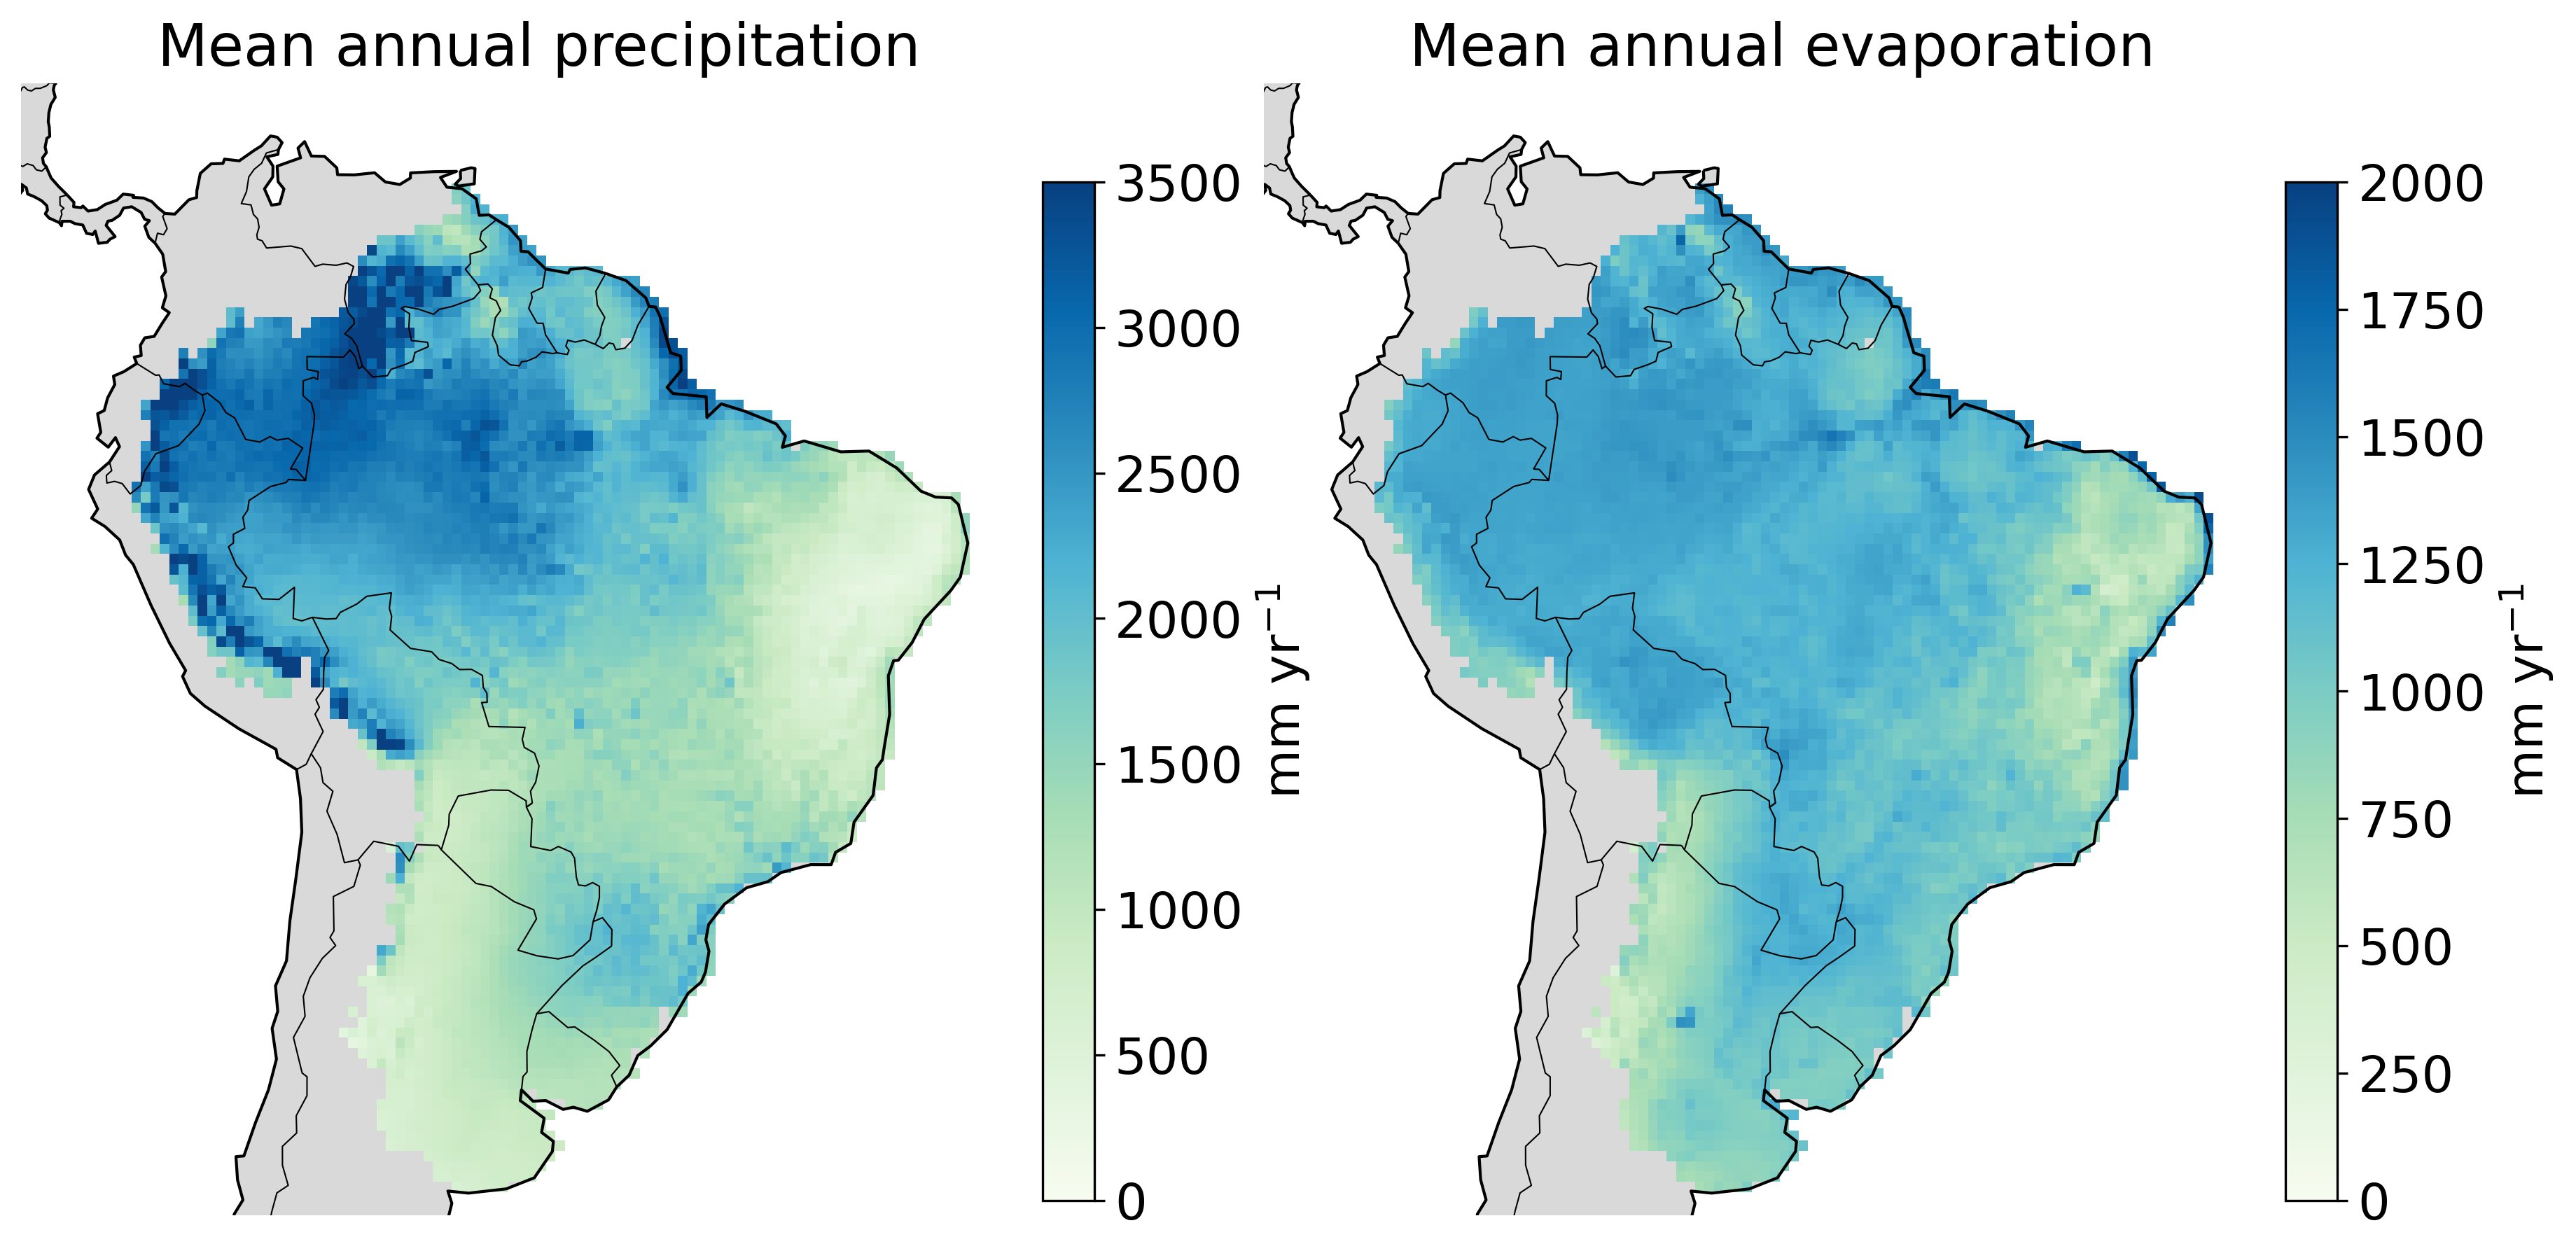

In [47]:
fig = plt.figure(figsize=(14,7), dpi = 300)
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
    
im = P_era5.where(Stakeholder[:-1].values > 0).plot(add_colorbar=False, ax = ax[0], cmap = 'GnBu', vmin = 0, vmax = 3500)
ax[0].set_title('Mean annual precipitation', fontsize = '20')
axs = inset_axes(ax[0], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[0].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.set_label(label = r'mm ${\mathrm{yr}^{-1}}$', size='xx-large')
cb.ax.tick_params(labelsize='xx-large')
#ax[0].set_title('Precipitation originating from \nupwind sources', fontsize = '20')

im = E_era5.where(Stakeholder[:-1].values > 0).plot(add_colorbar=False, ax = ax[1], cmap = 'GnBu', vmin = 0, vmax = 2000)
ax[1].set_title('Mean annual evaporation', fontsize = '20')
axs = inset_axes(ax[1], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[1].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.set_label(label = r'mm ${\mathrm{yr}^{-1}}$', size='xx-large')
cb.ax.tick_params(labelsize='xx-large')

In [3]:
##### Loading data

In [4]:
LU_Mapbiomas = xr.open_dataset('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif').band_data[0,::-1]
LU_Mapbiomas['x'] = LU_Mapbiomas.x.values%360
LU_Mapbiomas = LU_Mapbiomas.sortby('x')
LU_Mapbiomas = LU_Mapbiomas.sel(y = slice(-45, 15), x = slice(270, 330))

/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/plugins.py:64: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [5]:
data = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.nc')
data['x'] = data.x.values%360

/tmp/ipykernel_200440/308415755.py:1: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  data = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_Mapbiomas.nc')


In [6]:
E_era5 = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_evaporation/ERA5_daily/era5_evaporation_daily_daysum_*_p25.nc').e[:,::-1].sel(time = slice('2008','2017'), latitude = slice(-45, 15), longitude = slice(270, 330))
E_era5 = E_era5[:,:-1,:-1]*(-1000)
E_era5 = E_era5.resample(time = '1M').sum('time')
E_era5 = E_era5.coarsen(latitude = 2, longitude = 2).mean()

P_era5 = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_precipitation/ERA5_daily/era5_precipitation_daily_daysum_*_p25.nc').tp[:,::-1].sel(time = slice('2008','2017'), latitude = slice(-45, 15), longitude = slice(270, 330))
P_era5 = P_era5[:,:-1,:-1]*(1000)
P_era5 = P_era5.resample(time = '1M').sum('time')
P_era5 = P_era5.coarsen(latitude = 2, longitude = 2).mean()
P_era5_mean = (P_era5.groupby('time.month').mean('time')).values

CMIP_P_argmax = (P_era5.groupby('time.month').mean('time'))
CMIP_P_argmax = CMIP_P_argmax.argmax(axis = 0)
CMIP_P_argmax = CMIP_P_argmax.where(LU_Mapbiomas.values == 1).values

In [7]:
#RZS_TC = pd.read_pickle('/home/chandra/data/Stable_unstable_paper/Dataframe_updated_SA-29.03.2021.pkl')
RZS_TC = pd.read_pickle('/home/chandra/data/Stable_unstable_paper/Dataframe_updated_SA-29.03.2021.pkl')
for classes in [11,14,20,30,190,200,210,220]:
    RZS_TC = RZS_TC[RZS_TC.Landuse != int(classes)]

In [8]:
RZS_TC['Mean_TC'] = RZS_TC['Mean_Treecover']
RZS_TC[['Sr','MAP','Mean_Treecover','TC_f-i']].columns.values

RZS_TC.loc[RZS_TC['Mean_Treecover'] <= 50, 'Mean_Treecover' ] = 0
RZS_TC.loc[RZS_TC['Mean_Treecover'] > 50, 'Mean_Treecover' ] = 1

RZS_TC['TC_f-i_mod'] = RZS_TC['TC_f-i'].abs()

RZS_TC.rename(columns = {'TC_f-i_mod' : 'delTCmod'}, inplace = True)

print(RZS_TC['Sr'].where(RZS_TC['Mean_TC'] > 50).dropna().quantile(0.99))

RZS_TC['Sr_expendable'] = RZS_TC['Sr']

print('Sr_max_99th-percentile')
RZS_TC.loc[RZS_TC['Mean_TC'] < 30, 'Sr_expendable' ] = RZS_TC['Sr'].where(RZS_TC['Mean_TC'] > 50).dropna().quantile(0.99)

717.9348059082033
Sr_max_99th-percentile


In [9]:
### Running models

In [10]:
from statsmodels.formula.api import mnlogit
import statsmodels.api as sm
model_P = mnlogit("Mean_Treecover ~ MAP", RZS_TC).fit()
print(model_P.summary2())

Optimization terminated successfully.
         Current function value: 0.449438
         Iterations 7
                          Results: MNLogit
Model:                MNLogit          Pseudo R-squared: 0.351      
Dependent Variable:   Mean_Treecover   AIC:              638263.4565
Date:                 2022-10-31 09:35 BIC:              638286.4027
No. Observations:     710064           Log-Likelihood:   -3.1913e+05
Df Model:             1                LL-Null:          -4.9210e+05
Df Residuals:         710062           LLR p-value:      0.0000     
Converged:            1.0000           Scale:            1.0000     
No. Iterations:       7.0000                                        
--------------------------------------------------------------------
Mean_Treecover = 0  Coef.  Std.Err.     t     P>|t|   [0.025  0.975]
--------------------------------------------------------------------
         Intercept -3.8007   0.0095 -399.5920 0.0000 -3.8194 -3.7821
               MAP  0.0021 

In [11]:
from statsmodels.formula.api import mnlogit
import statsmodels.api as sm
model = mnlogit("Mean_Treecover ~ MAP+ Sr_expendable", RZS_TC).fit()
print(model.summary2())

Optimization terminated successfully.
         Current function value: 0.353325
         Iterations 7
                          Results: MNLogit
Model:                MNLogit          Pseudo R-squared: 0.490      
Dependent Variable:   Mean_Treecover   AIC:              501772.3430
Date:                 2022-10-31 09:35 BIC:              501806.7624
No. Observations:     710064           Log-Likelihood:   -2.5088e+05
Df Model:             2                LL-Null:          -4.9210e+05
Df Residuals:         710061           LLR p-value:      0.0000     
Converged:            1.0000           Scale:            1.0000     
No. Iterations:       7.0000                                        
--------------------------------------------------------------------
Mean_Treecover = 0  Coef.  Std.Err.     t     P>|t|   [0.025  0.975]
--------------------------------------------------------------------
         Intercept  0.7471   0.0161   46.3284 0.0000  0.7155  0.7787
               MAP  0.0015 

In [12]:
if Prec == 'CHIRPS':
    Precipitation = xr.open_mfdataset('/home/chandra/data/CHIRPS_Precipitation/Chirps/chirps-v2.0.20*.days_p25.nc').sel(time = slice('2008','2017')).precip
    Precipitation = Precipitation.resample(time = '1Y').sum('time')
    Precipitation = Precipitation.mean(axis = 0)
    Precipitation = Precipitation.coarsen(latitude = 2, longitude = 2).mean()
    Precipitation['longitude'] = Precipitation.longitude.values%360
    Precipitation = Precipitation.sortby('longitude')
    Precipitation = Precipitation.sel(latitude = slice(-45, 15), longitude = slice(270, 330))
    Precipitation = Precipitation.where(LU_Mapbiomas.values == 1)

if Prec == 'ERA5':
    Precipitation = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_precipitation/ERA5_daily/era5_precipitation_daily_daysum_*_p25.nc').tp[:,::-1].sel(time = slice('2008','2017'), latitude = slice(-45, 15), longitude = slice(270, 330))
    Precipitation.values = Precipitation.values*(1000)
    Precipitation = (Precipitation.resample(time = '1Y').sum('time'))[:,:-1,:-1].mean(axis = 0)
    Precipitation = Precipitation.coarsen(latitude = 2, longitude = 2).mean()
    Precipitation = Precipitation.where(LU_Mapbiomas.values == 1)

In [13]:
if Prec == 'CHIRPS':
    Sr = xr.open_dataset('/home/chandra/data/Paper4/Data_previous_literature/Data_Rootzone-storage-capacity.nc').mle_gumbel[0]
    #Sr['lon'] = Sr.lon.values%360
    Sr = Sr.coarsen(lat = 2, lon = 2).mean()
    Sr = Sr.sel(lat = slice(-45, 15), lon = slice(270, 330))
    Sr = Sr.where(LU_Mapbiomas.values == 1)
    
if Prec == 'ERA5':
    Sr_daily = xr.open_dataset('/home/chandra/data/Paper4/Data_previous_literature/Data_Rootzone-storage-capacity.nc').mle_gumbel[0]
    #Sr['lon'] = Sr.lon.values%360
    Sr_daily = Sr_daily.coarsen(lat = 2, lon = 2).mean()
    Sr_daily = Sr_daily.sel(lat = slice(-45, 15), lon = slice(270, 330))
    Sr_daily = Sr_daily.where(LU_Mapbiomas.values == 1)
    
    Sr = xr.open_dataset('/home/chandra/data/Paper4/Data_previous_literature/Max_Rootzone_20-years-return_Era5_0.25res_2008-2017_mle(skextremes).nc').mle_gumbel
    Sr = Sr.coarsen(lat = 2, lon = 2).mean()
    Sr = Sr.where(LU_Mapbiomas.values == 1)

'\nimport string\naxs = ax.flat\nfor n, ax in enumerate(axs):\n    ax.text(-0.25, 1.05, string.ascii_lowercase[n], transform=ax.transAxes, \n                    size=35)\n'

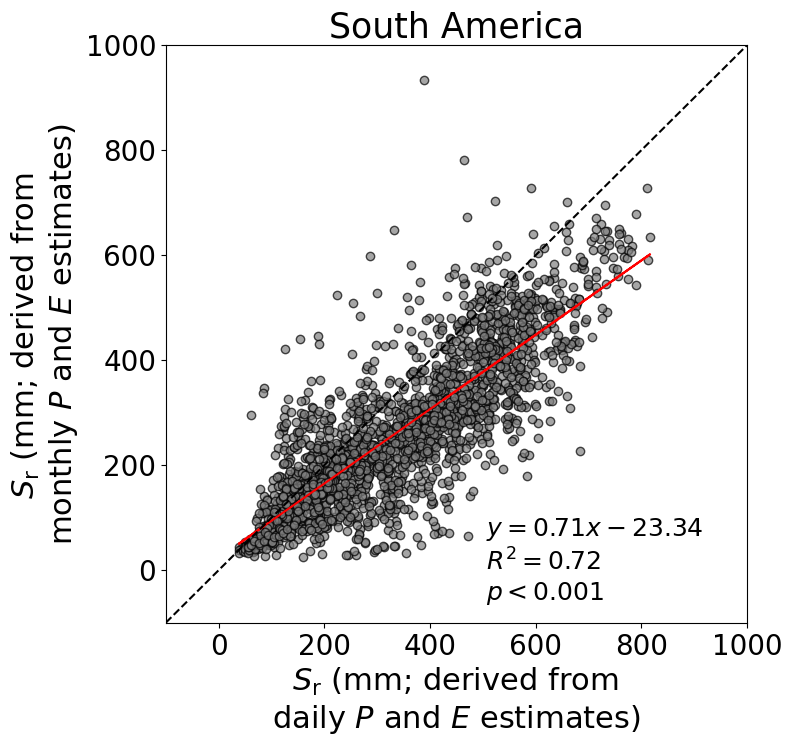

In [14]:
def Sr_slice(Sr, Sr_monthly, ax=None, **kwargs):
    #return Sr, Sr_monthly
    global model_reg

    import pandas as pd
    import matplotlib.pyplot as plt
    from sklearn import linear_model

    ######################################## Data preparation #########################################
    temp = pd.DataFrame({'Sr': Sr.values.flatten(), 
                             'Sr_monthly': Sr_monthly.values.flatten()}, columns=['Sr', 'Sr_monthly']).dropna()
    X = temp['Sr'].values.reshape(-1,1)
    y = temp['Sr_monthly'].values
        ################################################ Train #############################################

    ols = linear_model.LinearRegression()
    model_reg = ols.fit(X, y)
    response = model_reg.predict(X)
        ############################################## Evaluate ############################################
    r2 = model_reg.score(X, y)

    X2 = sm.add_constant(X)
    est = sm.OLS(y, X2)
    est2 = est.fit()
    p_value = est2.pvalues

        ############################################## Plot ################################################
    #fig, ax = plt.subplots(figsize=(5, 5))

    ax.plot(X, response, color='r', label='Regression model')
    ax.scatter(X, y, edgecolor='k', facecolor='grey', alpha=0.7, label='Sample data')
    ax.set_ylabel('$S_{\mathrm{r}}$ (mm; derived from \nmonthly $P$ and $E$ estimates)', fontsize=22)
    ax.set_xlabel('$S_{\mathrm{r}}$ (mm; derived from \ndaily $P$ and $E$ estimates)', fontsize=22)
    #ax.legend(facecolor='white', fontsize=11)
    ax.text(0.55, 0.15, '$y = %.2f x - %.2f $' % (model_reg.coef_[0], abs(model_reg.intercept_)), 
                fontsize=18, transform=ax.transAxes)
    ax.text(0.55, 0.09,'$R^2= %.2f$' % r2, fontsize=18, transform=ax.transAxes)
    if p_value[1] < 0.001:
        ax.text(0.55, 0.04,'$\mathit{p < 0.001}$', fontsize=18, transform=ax.transAxes)
    else:
        ax.text(0.55, 0.04,'$\mathit{p = %.2f}$' % p_value[1], fontsize=18, transform=ax.transAxes)
    ax.set_xlim(-100,1000)
    ax.set_ylim(-100,1000)
    ax.plot([-100,1000],[-100,1000], color='k', ls = '--')
    ax.tick_params(axis='both', which='major', labelsize=20)

fig, ax = plt.subplots(figsize=(7.5, 7.5))
Sr_slice(Sr_daily, Sr, ax = ax)
ax.set_title('South America', fontsize = 25)
"""
import string
axs = ax.flat
for n, ax in enumerate(axs):
    ax.text(-0.25, 1.05, string.ascii_lowercase[n], transform=ax.transAxes, 
                    size=35)
"""
#fig.savefig(parent_dir+'/Figures/Supplementary_Fig21_Sr_comparison(daily-monthly).tif', dpi=300)

In [16]:
## Analysing resilience

In [15]:
%%time
dataframe = pd.DataFrame({'MAP': Precipitation.values.flatten(), 'Sr_expendable': Sr_daily.values.flatten()})
#dataframe = dataframe.where(dataframe.Mean_TC > 50)
prediction = model.predict(sm.add_constant(dataframe[['MAP','Sr_expendable']]))[1].values
prediction = prediction.reshape(120, 120)

prediction = xr.DataArray(prediction, coords=[Sr.lat.values, Sr.lon.values], dims=['lat', 'lon'], 
             name = 'Resilience', attrs=dict(description="Resilience", units="Dimentionless"))
#prediction = prediction.where(LU_Mapbiomas.values == 1)

#prediction.to_netcdf('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr.nc')

CPU times: user 325 ms, sys: 262 ms, total: 587 ms
Wall time: 29.4 ms


In [16]:
%%time
prediction_P = model_P.predict(sm.add_constant(dataframe[['MAP']]))[1].values
prediction_P = prediction_P.reshape(120, 120)

prediction_P = xr.DataArray(prediction_P, coords=[Sr.lat.values, Sr.lon.values], dims=['lat', 'lon'], 
             name = 'Resilience', attrs=dict(description="Resilience", units="Dimentionless"))
prediction_P = (prediction_P.values*(prediction/prediction))
#prediction_P = prediction_P.where(LU_Mapbiomas.values == 1)

#prediction_P.to_netcdf('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P.nc')

CPU times: user 200 ms, sys: 221 ms, total: 421 ms
Wall time: 22.3 ms


In [3]:
import skextremes as ske

162.0777717259429
130.58815211740503


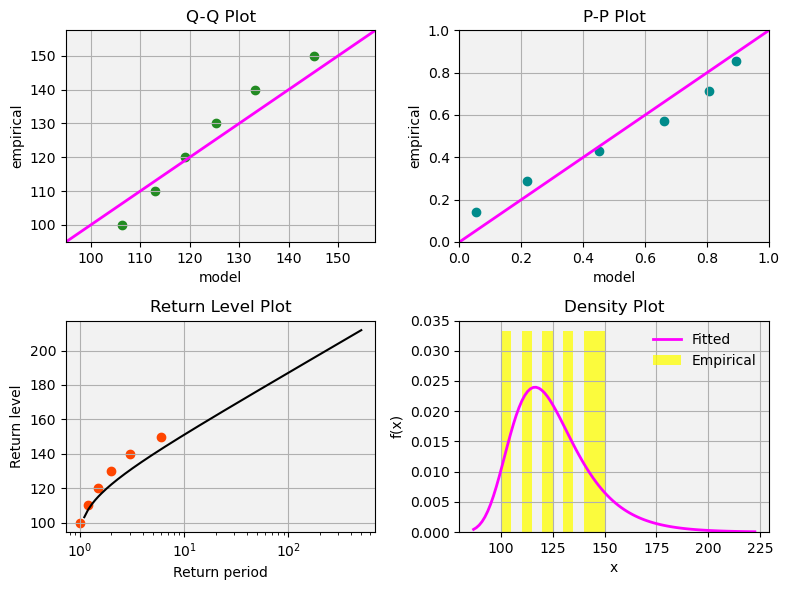

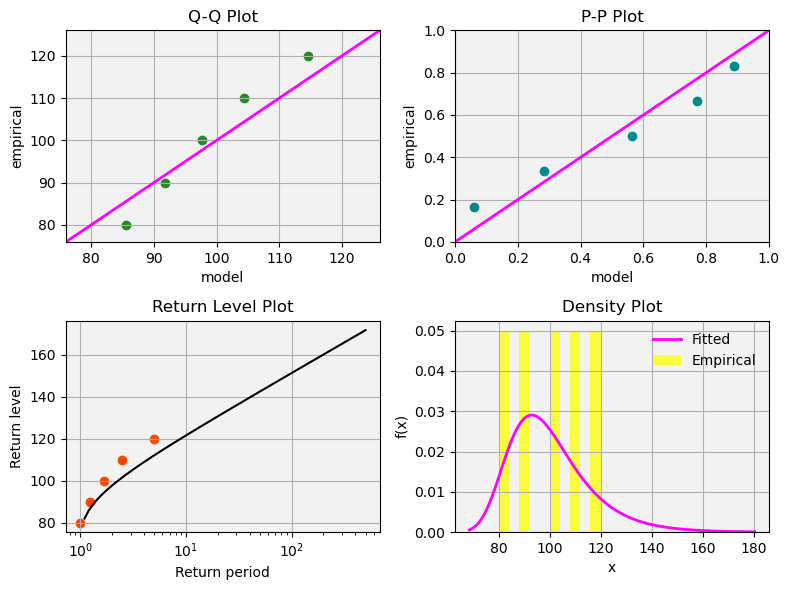

In [17]:
model = (ske.models.classic.Gumbel([100,110,120,130,140,150], fit_method = 'mle', return_periods=20))
model.plot_summary()
print(model.return_values)

model = (ske.models.classic.Gumbel([100,110,120,90,80], fit_method = 'mle', return_periods=20))
model.plot_summary()
print(model.return_values)

In [62]:
def Resilience_assessment(stakeholder,Landuse_map):
    global prediction_1, dataframe_2, prediction_2
    Evap_small = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))
    Evap_small = Evap_small[:,:,:-1]
    Evap_small = xr.where(Evap_small > P_era5_mean, P_era5_mean, Evap_small)
    
    Precipitation_1 = Precipitation-Evap_small.sum(dim = 'month').values

    dataframe_1 = pd.DataFrame({'MAP': Precipitation_1.values.flatten()})
    #dataframe = dataframe.where(dataframe.Mean_TC > 50)
    prediction_1 = model_P.predict(sm.add_constant(dataframe_1[['MAP']]))[1].values
    prediction_1 = prediction_1.reshape(120, 120)

    prediction_1 = xr.DataArray(prediction_1, coords=[Sr.lat.values, Sr.lon.values], dims=['lat', 'lon'], 
                 name = 'Resilience', attrs=dict(description="Resilience", units="Dimentionless"))
    prediction_1.to_netcdf('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P_'+stakeholder+'_'+Landuse_map+'.nc')
    
    Evap_small_1 = np.concatenate((Evap_small, Evap_small, Evap_small, Evap_small, Evap_small,
                    Evap_small, Evap_small, Evap_small, Evap_small, Evap_small), axis=0)

    year_start = 2008
    year_end = 2017

    sum_of_day = []
    year = 0
    #CMIP6_evap = E_era5
    #CMIP6_prec = P_era5

    deficit_all = (E_era5) - np.array(P_era5-Evap_small_1)
    max_deficit_annual = np.zeros((year_end-year_start,CMIP_P_argmax.shape[0],CMIP_P_argmax.shape[1]))

    year = 0
    for year in tqdm(range(year_start,year_end)):
        deficit_all_numpy = deficit_all.sel(time = slice(str(year),str(year+1))).values
        for lat in range(CMIP_P_argmax.shape[0]):
            for long in range(CMIP_P_argmax.shape[1]):
                cummul_deficit = np.zeros((24))
                if np.isnan(CMIP_P_argmax[lat,long]):
                    continue
                else:
                    for i in range(int(CMIP_P_argmax[lat,long]),int(CMIP_P_argmax[lat,long]+12)):
                        cummul_deficit[i] = deficit_all_numpy[i,lat,long] + cummul_deficit[i-1]
                        if cummul_deficit[i] < 0:
                            cummul_deficit[i] = 0
                        else:
                            continue
                max_deficit_annual[year-year_start,lat,long] = np.nanmax(cummul_deficit)

    Annual_deficit = xr.DataArray(max_deficit_annual, coords=[np.arange(year_start,year_end,1), E_era5.latitude.values, E_era5.longitude.values],
                             dims=['year', 'lat', 'lon'], name = 'annual_water_deficit', attrs=dict(description="Annual Water Deficit", units="mm/year"))

    import skextremes as ske
    Sr_monthly = np.zeros((Annual_deficit.values.shape[1], Annual_deficit.values.shape[2]))
    for lat in tqdm(range(Annual_deficit.values.shape[1])):
        for lon in range(Annual_deficit.values.shape[2]):
            if Annual_deficit[:,lat,lon].values.sum() == 0:
                continue
            else:
                WD_cal = (Annual_deficit[:,lat,lon].values)
                model1 = ske.models.classic.Gumbel(WD_cal, fit_method = 'mle', return_periods=20);
                Sr_monthly[lat,lon] = (model1.return_values)

    Sr_monthly = xr.DataArray(Sr_monthly, coords=[E_era5.latitude.values, E_era5.longitude.values], dims=['lat', 'lon'], name = 'Sr', 
                            attrs=dict(description="Root zone storage capacity", units="mm/year"))
    Sr_monthly = Sr_monthly.fillna(0)
    Sr_monthly = Sr_monthly.where(LU_Mapbiomas.values == 1)

    dataframe_2 = pd.DataFrame({'MAP': Precipitation_1.values.flatten(), 'Sr_expendable': ((Sr_monthly.values.flatten()+abs(model_reg.intercept_))/model_reg.coef_[0])})
    #dataframe = dataframe.where(dataframe.Mean_TC > 50)
    prediction_2 = model.predict(sm.add_constant(dataframe_2[['MAP','Sr_expendable']]))[1].values
    prediction_2 = prediction_2.reshape(120, 120)

    prediction_2 = xr.DataArray(prediction_2, coords=[Sr_monthly.lat.values, Sr_monthly.lon.values], dims=['lat', 'lon'], 
                 name = 'Resilience', attrs=dict(description="Resilience", units="Dimentionless"))
    prediction_2.to_netcdf('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_'+stakeholder+'_'+Landuse_map+'.nc')
    return prediction_1, prediction_2
    

In [25]:
def CF_Resilience_assessment(stakeholder,Landuse_map, decrease_by_percent):
    global prediction_1, dataframe_2, prediction_2
    Evap_small = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))
    Evap_small = Evap_small[:,:,:-1]
    Evap_small = Evap_small*decrease_by_percent/100
    Evap_small = xr.where(Evap_small > P_era5_mean, P_era5_mean, Evap_small)
    
    Precipitation_1 = Precipitation-Evap_small.sum(dim = 'month').values

    dataframe_1 = pd.DataFrame({'MAP': Precipitation_1.values.flatten()})
    #dataframe = dataframe.where(dataframe.Mean_TC > 50)
    prediction_1 = model_P.predict(sm.add_constant(dataframe_1[['MAP']]))[1].values
    prediction_1 = prediction_1.reshape(120, 120)

    prediction_1 = xr.DataArray(prediction_1, coords=[Sr.lat.values, Sr.lon.values], dims=['lat', 'lon'], 
                 name = 'Resilience', attrs=dict(description="Resilience", units="Dimentionless"))
    prediction_1.to_netcdf('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P_'+stakeholder+'_'+Landuse_map+'_'+str(decrease_by_percent)+'decrease.nc')
    
    Evap_small_1 = np.concatenate((Evap_small, Evap_small, Evap_small, Evap_small, Evap_small,
                    Evap_small, Evap_small, Evap_small, Evap_small, Evap_small), axis=0)

    year_start = 2008
    year_end = 2017

    sum_of_day = []
    year = 0
    #CMIP6_evap = E_era5
    #CMIP6_prec = P_era5

    deficit_all = (E_era5) - np.array(P_era5-Evap_small_1)
    max_deficit_annual = np.zeros((year_end-year_start,CMIP_P_argmax.shape[0],CMIP_P_argmax.shape[1]))

    year = 0
    for year in tqdm(range(year_start,year_end)):
        deficit_all_numpy = deficit_all.sel(time = slice(str(year),str(year+1))).values
        for lat in range(CMIP_P_argmax.shape[0]):
            for long in range(CMIP_P_argmax.shape[1]):
                cummul_deficit = np.zeros((24))
                if np.isnan(CMIP_P_argmax[lat,long]):
                    continue
                else:
                    for i in range(int(CMIP_P_argmax[lat,long]),int(CMIP_P_argmax[lat,long]+12)):
                        cummul_deficit[i] = deficit_all_numpy[i,lat,long] + cummul_deficit[i-1]
                        if cummul_deficit[i] < 0:
                            cummul_deficit[i] = 0
                        else:
                            continue
                max_deficit_annual[year-year_start,lat,long] = np.nanmax(cummul_deficit)

    Annual_deficit = xr.DataArray(max_deficit_annual, coords=[np.arange(year_start,year_end,1), E_era5.latitude.values, E_era5.longitude.values],
                             dims=['year', 'lat', 'lon'], name = 'annual_water_deficit', attrs=dict(description="Annual Water Deficit", units="mm/year"))

    import skextremes as ske
    Sr_monthly = np.zeros((Annual_deficit.values.shape[1], Annual_deficit.values.shape[2]))
    for lat in tqdm(range(Annual_deficit.values.shape[1])):
        for lon in range(Annual_deficit.values.shape[2]):
            if Annual_deficit[:,lat,lon].values.sum() == 0:
                continue
            else:
                WD_cal = (Annual_deficit[:,lat,lon].values)
                model1 = ske.models.classic.Gumbel(WD_cal, fit_method = 'mle', return_periods=20);
                Sr_monthly[lat,lon] = (model1.return_values)

    Sr_monthly = xr.DataArray(Sr_monthly, coords=[E_era5.latitude.values, E_era5.longitude.values], dims=['lat', 'lon'], name = 'Sr', 
                            attrs=dict(description="Root zone storage capacity", units="mm/year"))
    Sr_monthly = Sr_monthly.fillna(0)
    Sr_monthly = Sr_monthly.where(LU_Mapbiomas.values == 1)

    dataframe_2 = pd.DataFrame({'MAP': Precipitation_1.values.flatten(), 'Sr_expendable': ((Sr_monthly.values.flatten()+abs(model_reg.intercept_))/model_reg.coef_[0])})
    #dataframe = dataframe.where(dataframe.Mean_TC > 50)
    prediction_2 = model.predict(sm.add_constant(dataframe_2[['MAP','Sr_expendable']]))[1].values
    prediction_2 = prediction_2.reshape(120, 120)

    prediction_2 = xr.DataArray(prediction_2, coords=[Sr_monthly.lat.values, Sr_monthly.lon.values], dims=['lat', 'lon'], 
                 name = 'Resilience', attrs=dict(description="Resilience", units="Dimentionless"))
    prediction_2.to_netcdf('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_'+stakeholder+'_'+Landuse_map+'_'+str(decrease_by_percent)+'decrease.nc')
    return prediction_1, prediction_2
    

In [26]:
for i in ['Smallholders','Mediumholders','Largeholders']:
    CF_Resilience_assessment(i, Landuse_map, 80)

100%|██████████| 120/120 [00:08<00:00, 13.86it/s]


In [38]:
for i in ['Smallholders','Mediumholders','Largeholders']:
    CF_Resilience_assessment(i, Landuse_map, 50)

100%|██████████| 120/120 [00:08<00:00, 13.57it/s]


100%|██████████| 120/120 [00:09<00:00, 13.30it/s]


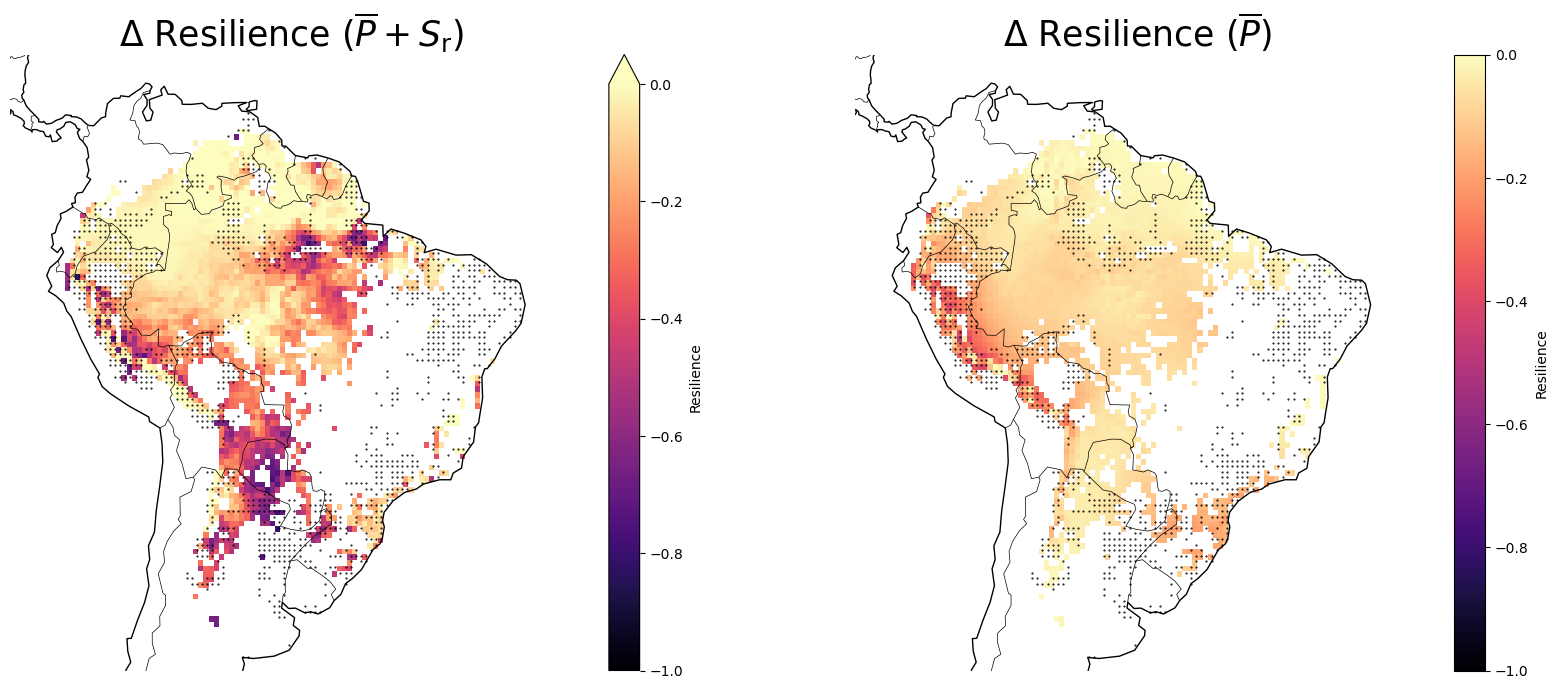

In [63]:
prediction_1, prediction_2 = Resilience_assessment('Smallholders', Landuse_map)

Stakeholder_int = 1
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

(prediction_2-prediction).plot(ax = ax[0], vmin = -1, vmax = 0, cmap = 'magma',)
Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Δ Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

(prediction_1-prediction_P).plot(ax = ax[1], vmin = -1, vmax = 0, cmap = 'magma',)
Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[1], s=1, marker=".", c='k')
ax[1].set_title('Δ Resilience ($\overline{P}$)', fontsize = '25')

for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()

100%|██████████| 120/120 [00:08<00:00, 13.55it/s]


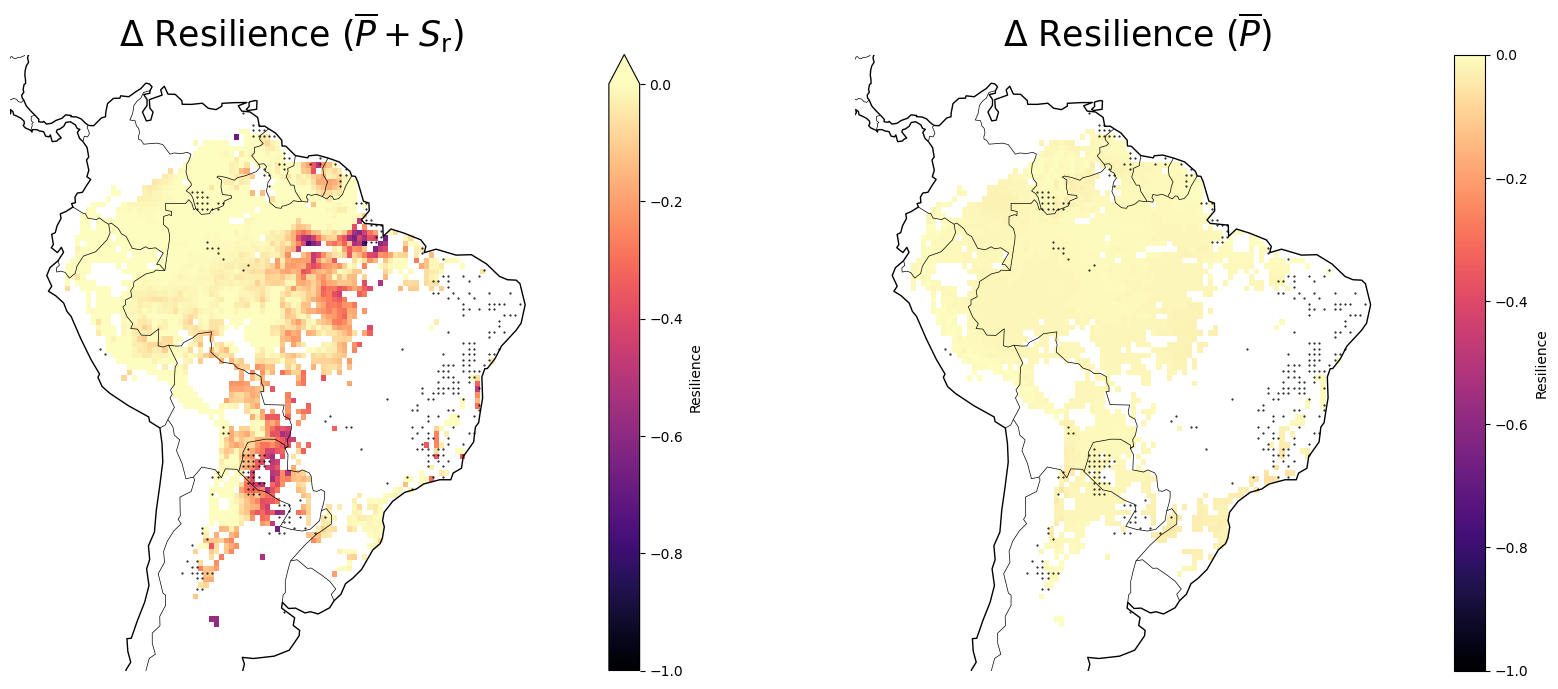

In [64]:
prediction_1, prediction_2 = Resilience_assessment('Mediumholders', Landuse_map)

Stakeholder_int = 2
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

(prediction_2-prediction).plot(ax = ax[0], vmin = -1, vmax = 0, cmap = 'magma',)
Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Δ Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

(prediction_1-prediction_P).plot(ax = ax[1], vmin = -1, vmax = 0, cmap = 'magma',)
Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[1], s=1, marker=".", c='k')
ax[1].set_title('Δ Resilience ($\overline{P}$)', fontsize = '25')

for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()

100%|██████████| 120/120 [00:09<00:00, 13.30it/s]


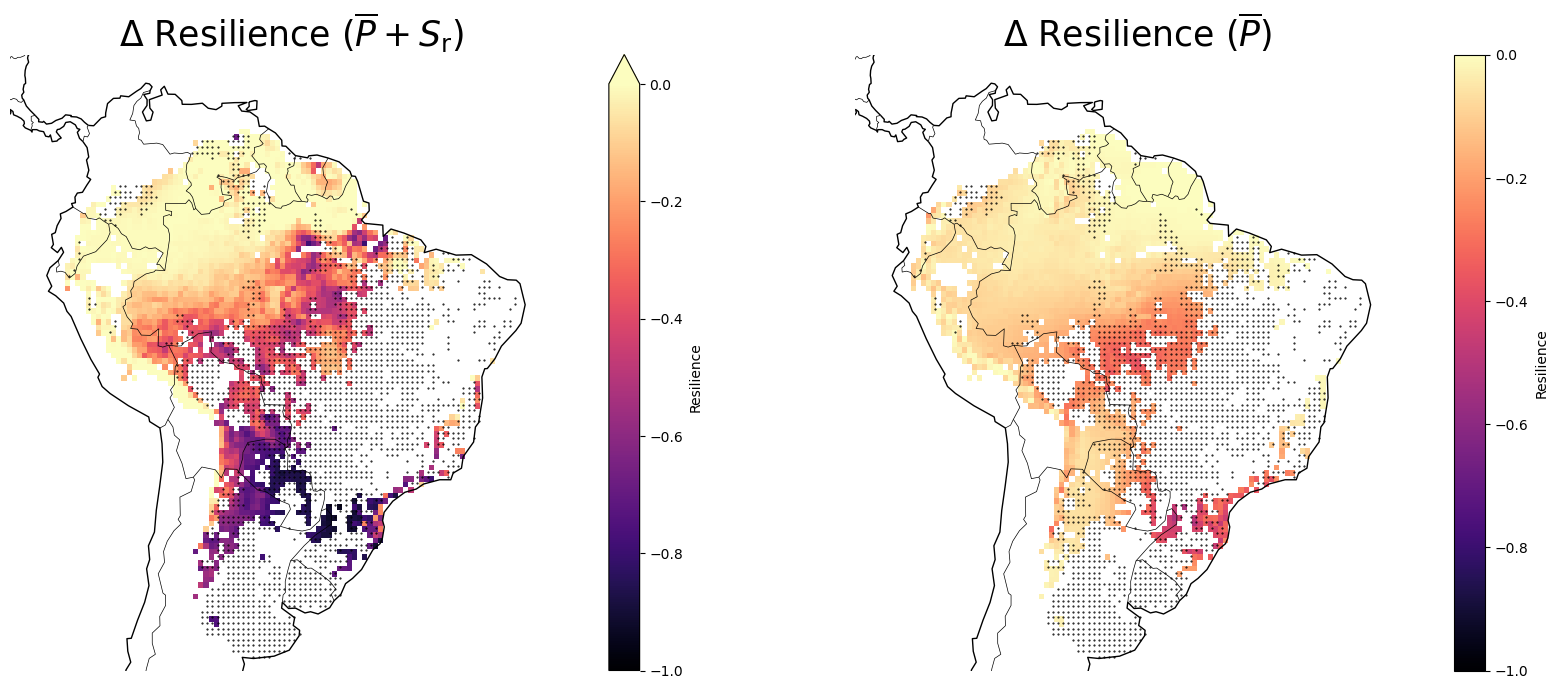

In [65]:
prediction_1, prediction_2 = Resilience_assessment('Largeholders', Landuse_map)

Stakeholder_int = 3
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

(prediction_2-prediction).plot(ax = ax[0], vmin = -1, vmax = 0, cmap = 'magma',)
Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Δ Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

(prediction_1-prediction_P).plot(ax = ax[1], vmin = -1, vmax = 0, cmap = 'magma',)
Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[1], s=1, marker=".", c='k')
ax[1].set_title('Δ Resilience ($\overline{P}$)', fontsize = '25')

for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()

In [40]:
def increase_res(prediction):
    increase_res = 20
    new_lon = np.linspace(prediction.lon[0].values, prediction.lon[-1].values, prediction.lon.shape[0]*increase_res)
    new_lat = np.linspace(prediction.lat[0].values, prediction.lat[-1].values, prediction.lat.shape[0]*increase_res)
    prediction = prediction.interp(lat=new_lat, lon=new_lon,method='linear')
    return prediction

In [29]:
Resilience = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr.nc').Resilience

In [30]:
Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]
Stakeholder['x'] = Stakeholder.x.values%360

/tmp/ipykernel_2389/3478874843.py:1: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]


In [8]:
MF_Large = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Largeholders_'+Landuse_map+'.nc').Evap_footprint
MF_Large = (MF_Large[:,::-1,:].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,1:])
MF_Large = xr.where(MF_Large > P_era5_mean, P_era5_mean, MF_Large)
MF_Large = MF_Large.sum(dim = 'month').sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))
MF_Large = MF_Large[:,1:].where(Stakeholder.values > 0)

MF_Medium = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Mediumholders_'+Landuse_map+'.nc').Evap_footprint
MF_Medium = (MF_Medium[:,::-1,:].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,1:])
MF_Medium = xr.where(MF_Medium > P_era5_mean, P_era5_mean, MF_Medium)
MF_Medium = MF_Medium.sum(dim = 'month').sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))
MF_Medium = MF_Medium[:,1:].where(Stakeholder.values > 0)

MF_Small = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Smallholders_'+Landuse_map+'.nc').Evap_footprint
MF_Small = (MF_Small[:,::-1,:].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,1:])
MF_Small = xr.where(MF_Small > P_era5_mean, P_era5_mean, MF_Small)
MF_Small = MF_Small.sum(dim = 'month').sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))
MF_Small = MF_Small[:,1:].where(Stakeholder.values > 0)

NameError: name 'P_era5_mean' is not defined

In [12]:
MF_Large_F = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Largeholders_'+Landuse_map+'_Forest_only.nc').Evap_footprint
MF_Large_F = (MF_Large_F[:,::-1,:].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,1:])
MF_Large_F = xr.where(MF_Large_F > P_era5_mean, P_era5_mean, MF_Large_F)
MF_Large_F = MF_Large_F.sum(dim = 'month').sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))
MF_Large_F = MF_Large_F[:,1:].where(Stakeholder.values > 0)

MF_Medium_F = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Mediumholders_'+Landuse_map+'_Forest_only.nc').Evap_footprint
MF_Medium_F = (MF_Medium_F[:,::-1,:].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,1:])
MF_Medium_F = xr.where(MF_Medium_F > P_era5_mean, P_era5_mean, MF_Medium_F)
MF_Medium_F = MF_Medium_F.sum(dim = 'month').sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))
MF_Medium_F = MF_Medium_F[:,1:].where(Stakeholder.values > 0)

MF_Small_F = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_Smallholders_'+Landuse_map+'_Forest_only.nc').Evap_footprint
MF_Small_F = (MF_Small_F[:,::-1,:].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,1:])
MF_Small_F = xr.where(MF_Small_F > P_era5_mean, P_era5_mean, MF_Small_F)
MF_Small_F = MF_Small_F.sum(dim = 'month').sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))
MF_Small_F = MF_Small_F[:,1:].where(Stakeholder.values > 0)

In [27]:
Large = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Largeholders_'+Landuse_map+'.nc').Resilience
Medium = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Mediumholders_'+Landuse_map+'.nc').Resilience
Small = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Smallholders_'+Landuse_map+'.nc').Resilience

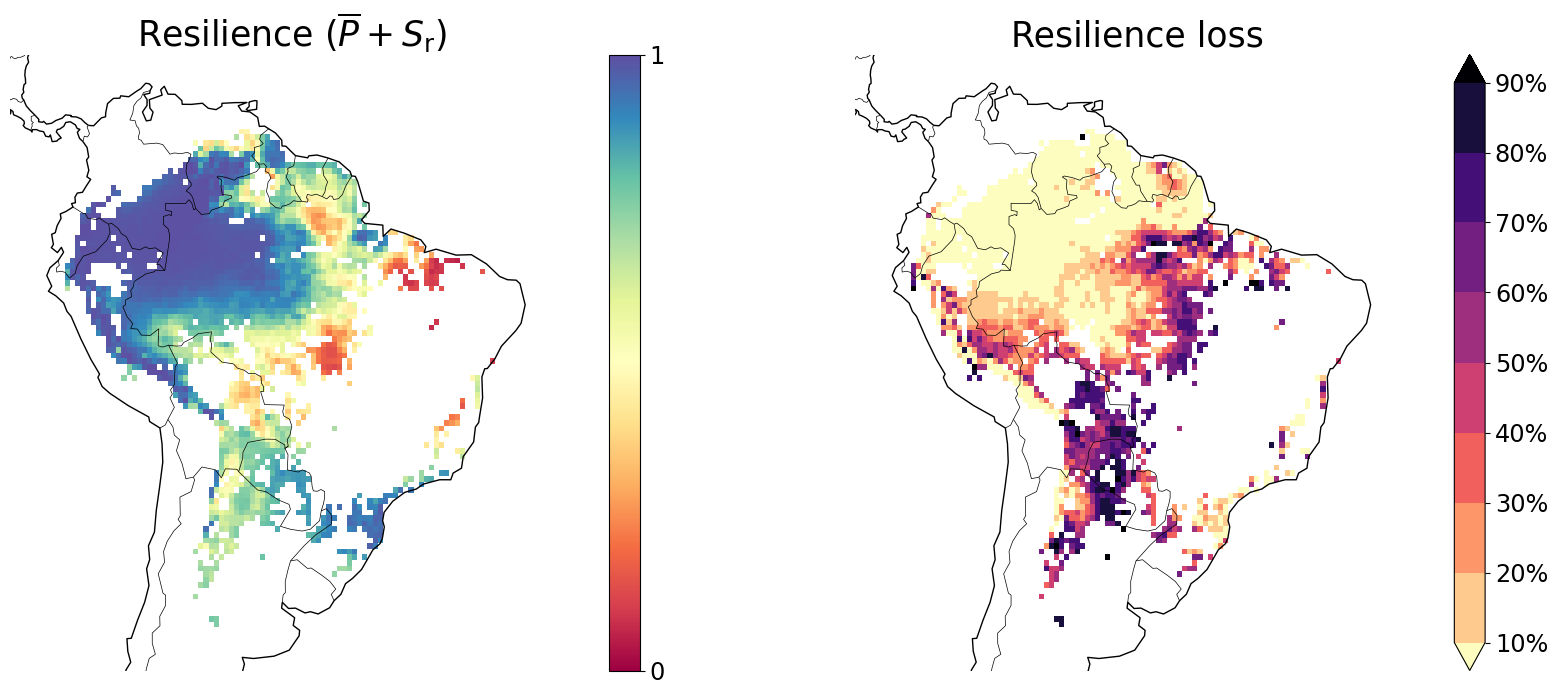

In [133]:
#Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = ((Resilience.values-Small)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'magma_r', levels = 9, extend= None)
cb = plt.colorbar(im, pad=0.05)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%', '90%']) 

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience loss', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()


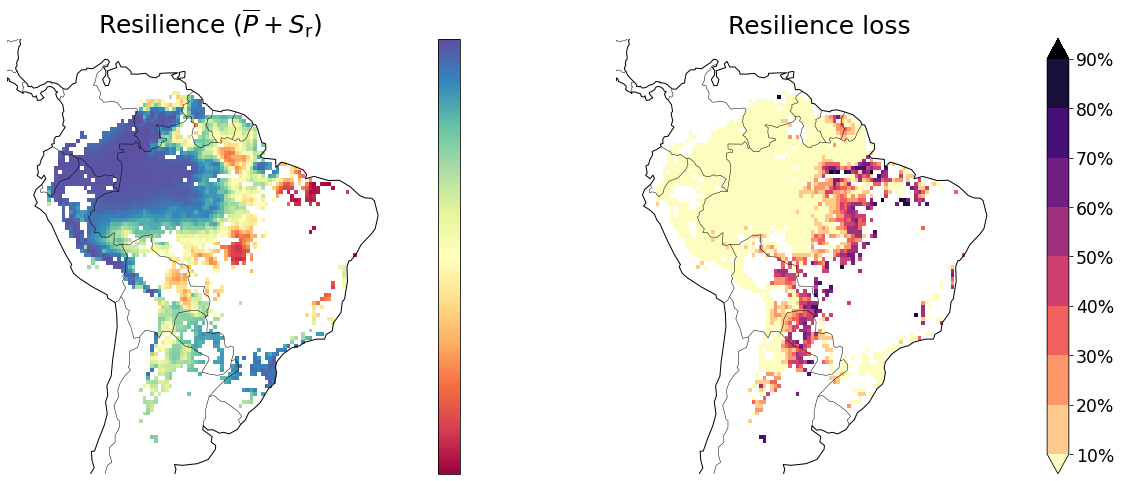

In [59]:
#Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0],cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = ((Resilience.values-Medium)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'magma_r', levels = 9, extend= None)
cb = plt.colorbar(im, pad=0.05)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%', '90%']) 


#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience loss', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()


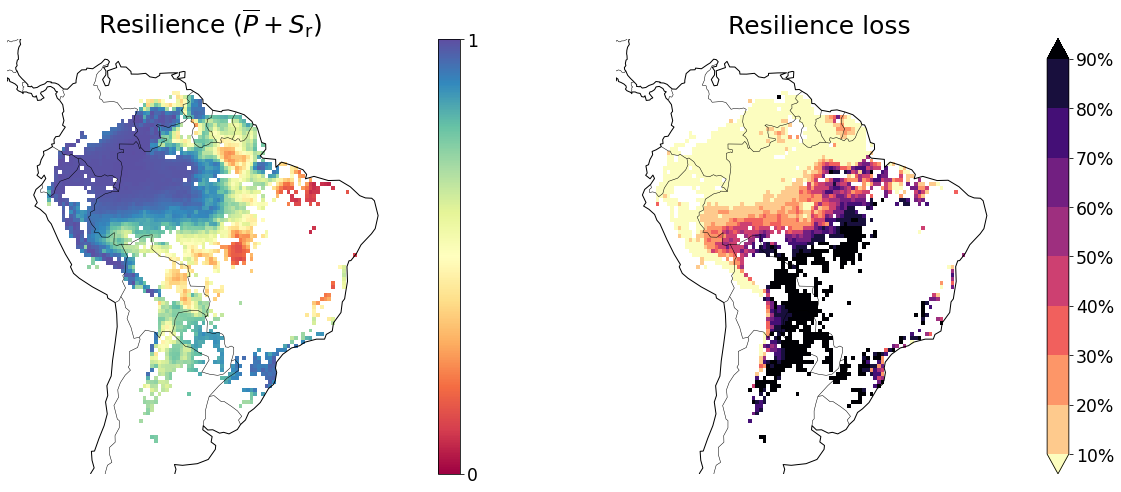

In [45]:
#Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = ((Resilience.values-Large)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'magma_r', levels = 9, extend= None)
cb = plt.colorbar(im, pad=0.05)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%', '90%']) 


#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience loss', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()

Text(0.5, 1.0, 'Large landholders \nforest')

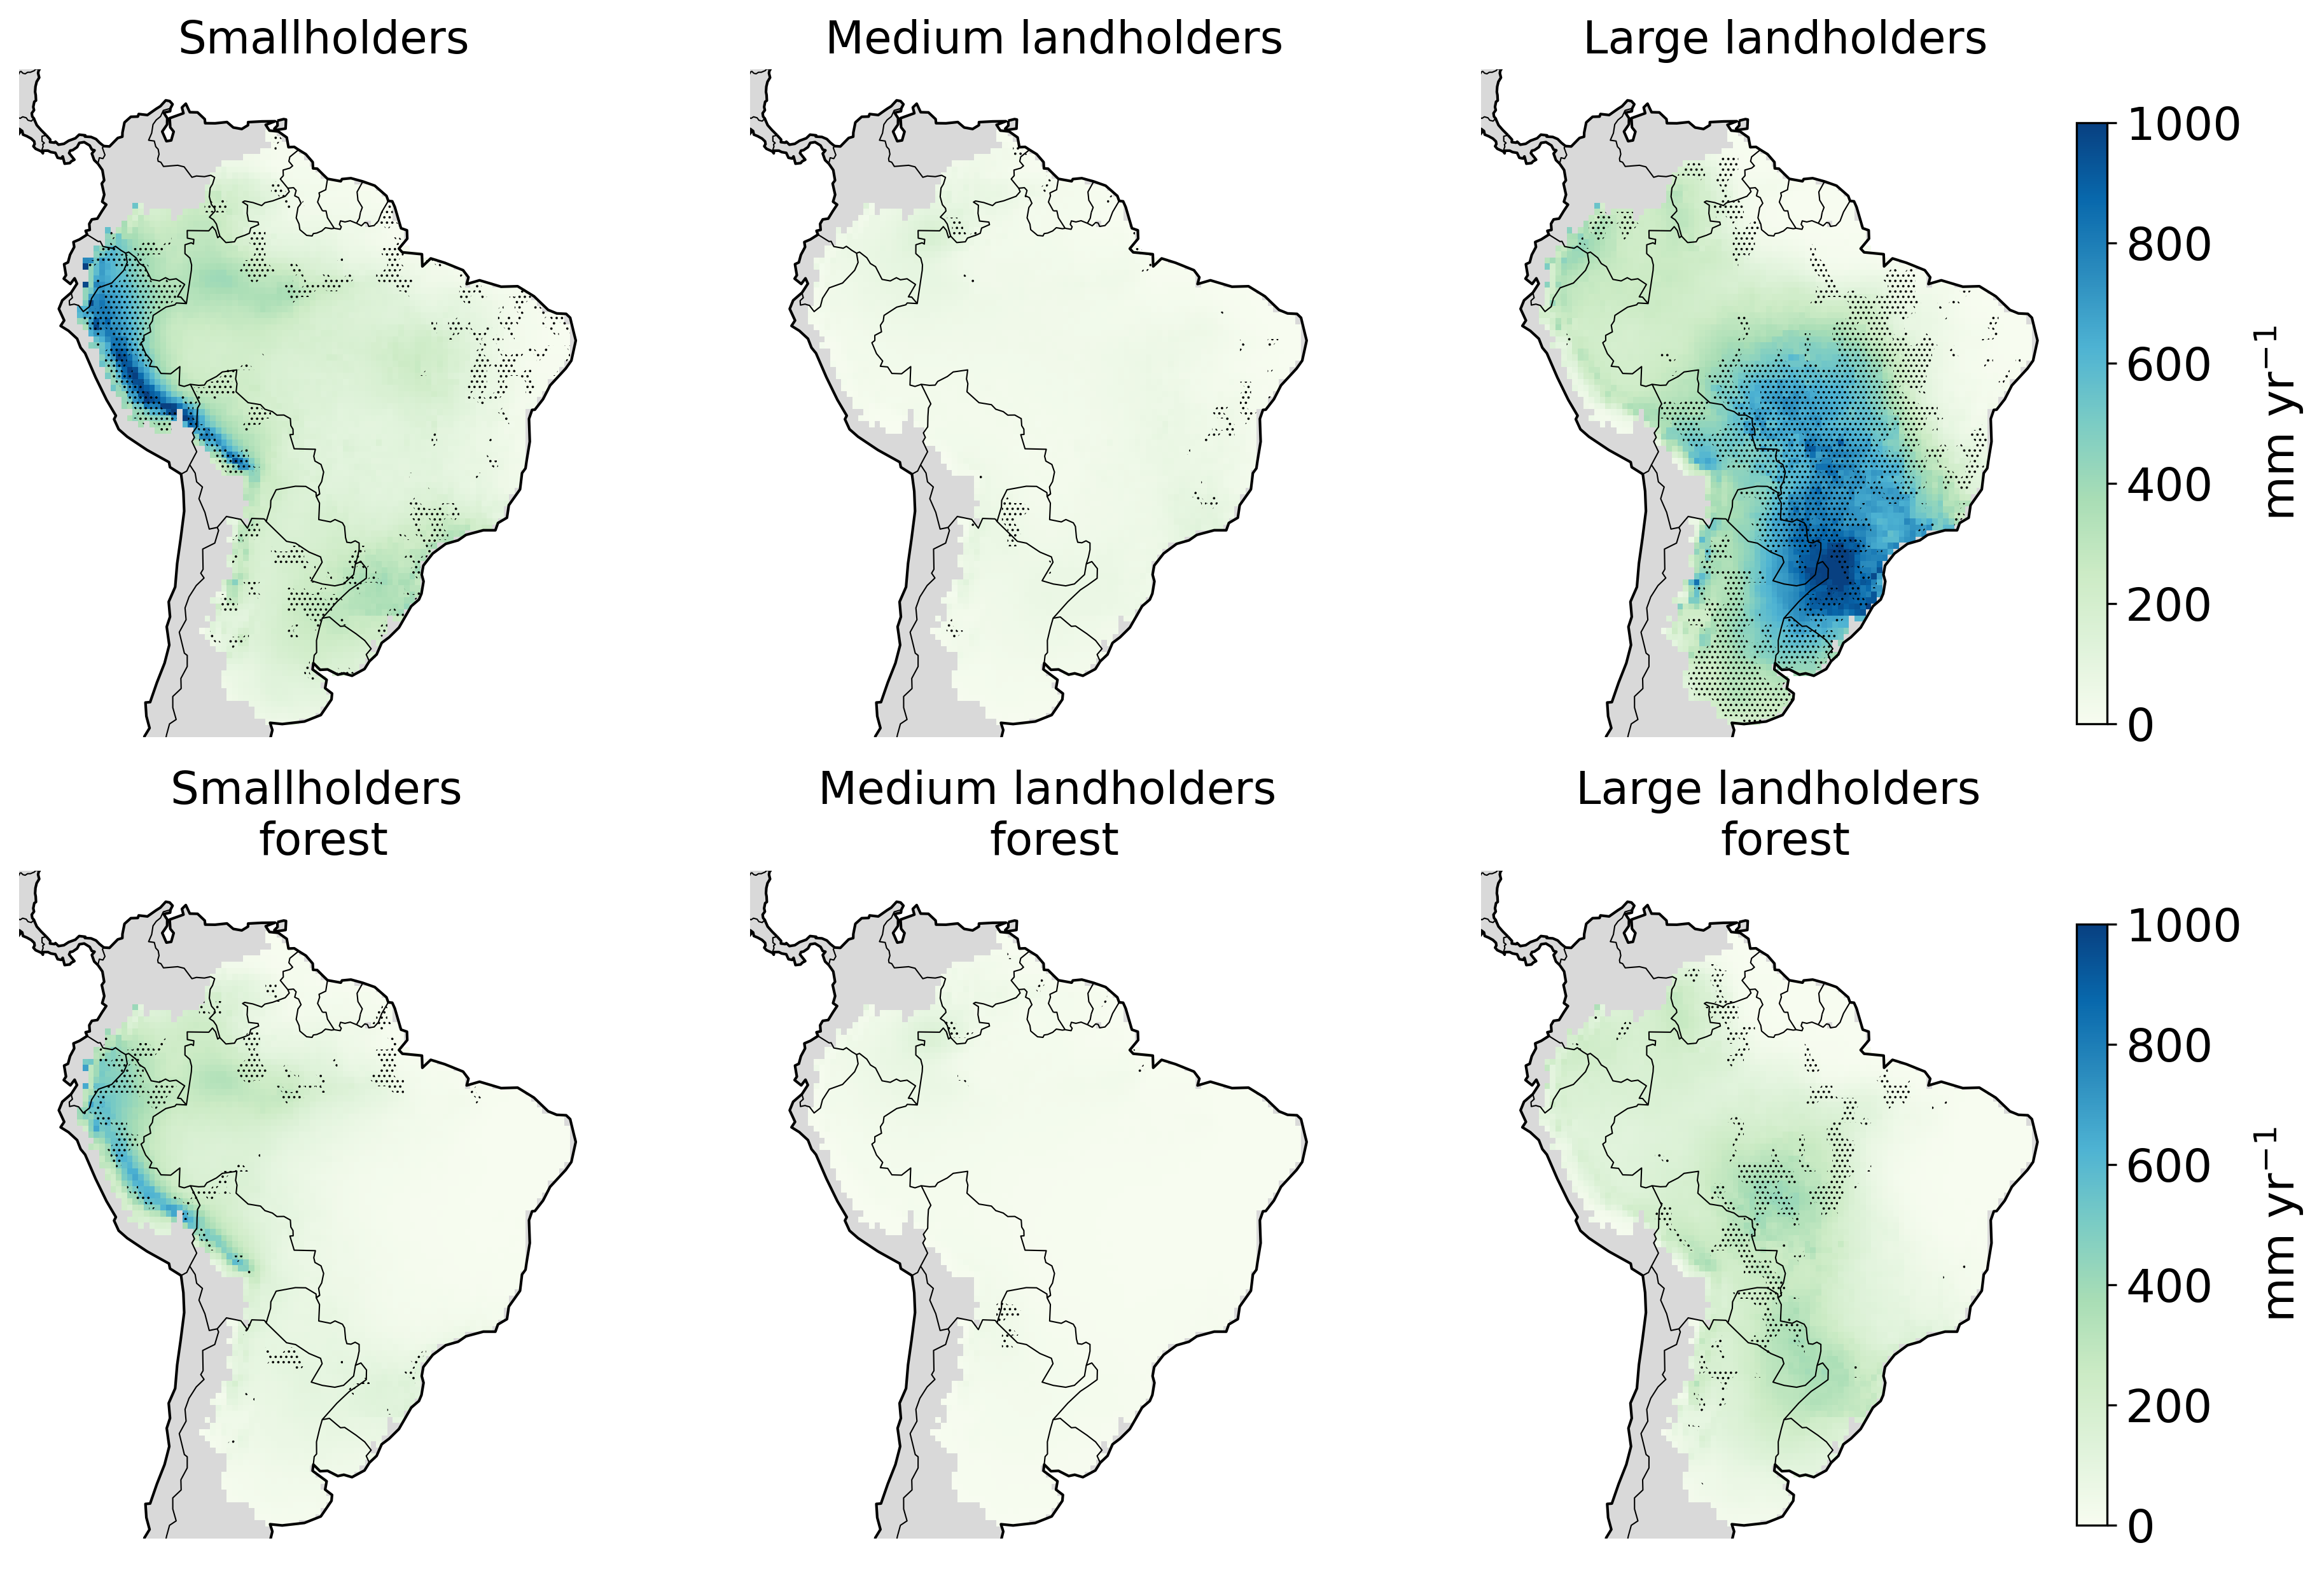

In [23]:

plt.rcParams['hatch.linewidth'] = 0.5

fig = plt.figure(figsize=(14,10), dpi = 300)
ax = [plt.subplot(231,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(232,projection=ccrs.PlateCarree(), aspect='auto'),
      plt.subplot(233,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(234,projection=ccrs.PlateCarree(), aspect='auto'), 
      plt.subplot(235,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(236,projection=ccrs.PlateCarree(), aspect='auto')]

for i in range(6):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
    
    
Stakeholder_int = 1
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = MF_Small.plot(add_colorbar=False, ax = ax[0], cmap = 'GnBu', vmin = 0, vmax = 1000)

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].contourf(Stakeholder.where(Stakeholder == 1).x.values, Stakeholder.where(Stakeholder == 1).y.values, 
             Stakeholder.where(Stakeholder == 1).values, hatches=['......'], colors='none')
ax[0].set_title('Smallholders', fontsize = '17')

#ax[0].set_title('Precipitation originating from \nupwind sources', fontsize = '20')


Stakeholder_int = 2
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = MF_Medium.plot(add_colorbar=False, ax = ax[1], cmap = 'GnBu', vmin = 0, vmax = 1000)

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[2], s=1, marker=".", c='k')
ax[1].contourf(Stakeholder.where(Stakeholder == 2).x.values, Stakeholder.where(Stakeholder == 2).y.values, 
             Stakeholder.where(Stakeholder == 2).values, hatches=['......'], colors='none')
ax[1].set_title('Medium landholders', fontsize = '17')


Stakeholder_int = 3
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = MF_Large.plot(add_colorbar=False, ax = ax[2], cmap = 'GnBu', vmin = 0, vmax = 1000)
axs = inset_axes(ax[2], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[2].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.set_label(label = r'mm ${\mathrm{yr}^{-1}}$', size='xx-large')
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[4], s=1, marker=".", c='black')
ax[2].contourf(Stakeholder.where(Stakeholder == 3).x.values, Stakeholder.where(Stakeholder == 3).y.values, 
             Stakeholder.where(Stakeholder == 3).values, hatches=['......'], colors='none')

ax[2].set_title('Large landholders', fontsize = '17')

#######################################################################

Stakeholder_int = 1
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = MF_Small_F.plot(add_colorbar=False, ax = ax[3], cmap = 'GnBu', vmin = 0, vmax = 1000)

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
y_forest = LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)).where((Stakeholder.values == 1) & 
                        (LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)) == 1))
ax[3].contourf(y_forest.x.values, y_forest.y.values, y_forest.values, hatches=['......'], colors='None')
ax[3].set_title('Smallholders \nforest', fontsize = '17')

#ax[0].set_title('Precipitation originating from \nupwind sources', fontsize = '20')


Stakeholder_int = 2
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = MF_Medium_F.plot(add_colorbar=False, ax = ax[4], cmap = 'GnBu', vmin = 0, vmax = 1000)

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[2], s=1, marker=".", c='k')
y_forest = LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)).where((Stakeholder.values == 2) & 
                        (LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)) == 1))
ax[4].contourf(y_forest.x.values, y_forest.y.values, y_forest.values, hatches=['......'], colors='None')
ax[4].set_title('Medium landholders \nforest', fontsize = '17')


Stakeholder_int = 3
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = MF_Large_F.plot(add_colorbar=False, ax = ax[5], cmap = 'GnBu', vmin = 0, vmax = 1000)
axs = inset_axes(ax[5], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[5].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.set_label(label = r'mm ${\mathrm{yr}^{-1}}$', size='xx-large')
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[4], s=1, marker=".", c='black')
y_forest = LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)).where((Stakeholder.values == 3) & 
                        (LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)) == 1))
ax[5].contourf(y_forest.x.values, y_forest.y.values, y_forest.values, hatches=['......'], colors='None')
ax[5].set_title('Large landholders \nforest', fontsize = '17')

#plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0.1)
#plt.show()
#plt.savefig('/home/chandra/data/Paper4/Output/Moisture_flows_assessments/Moisture_forwardtracking.svg', dpi = 10)

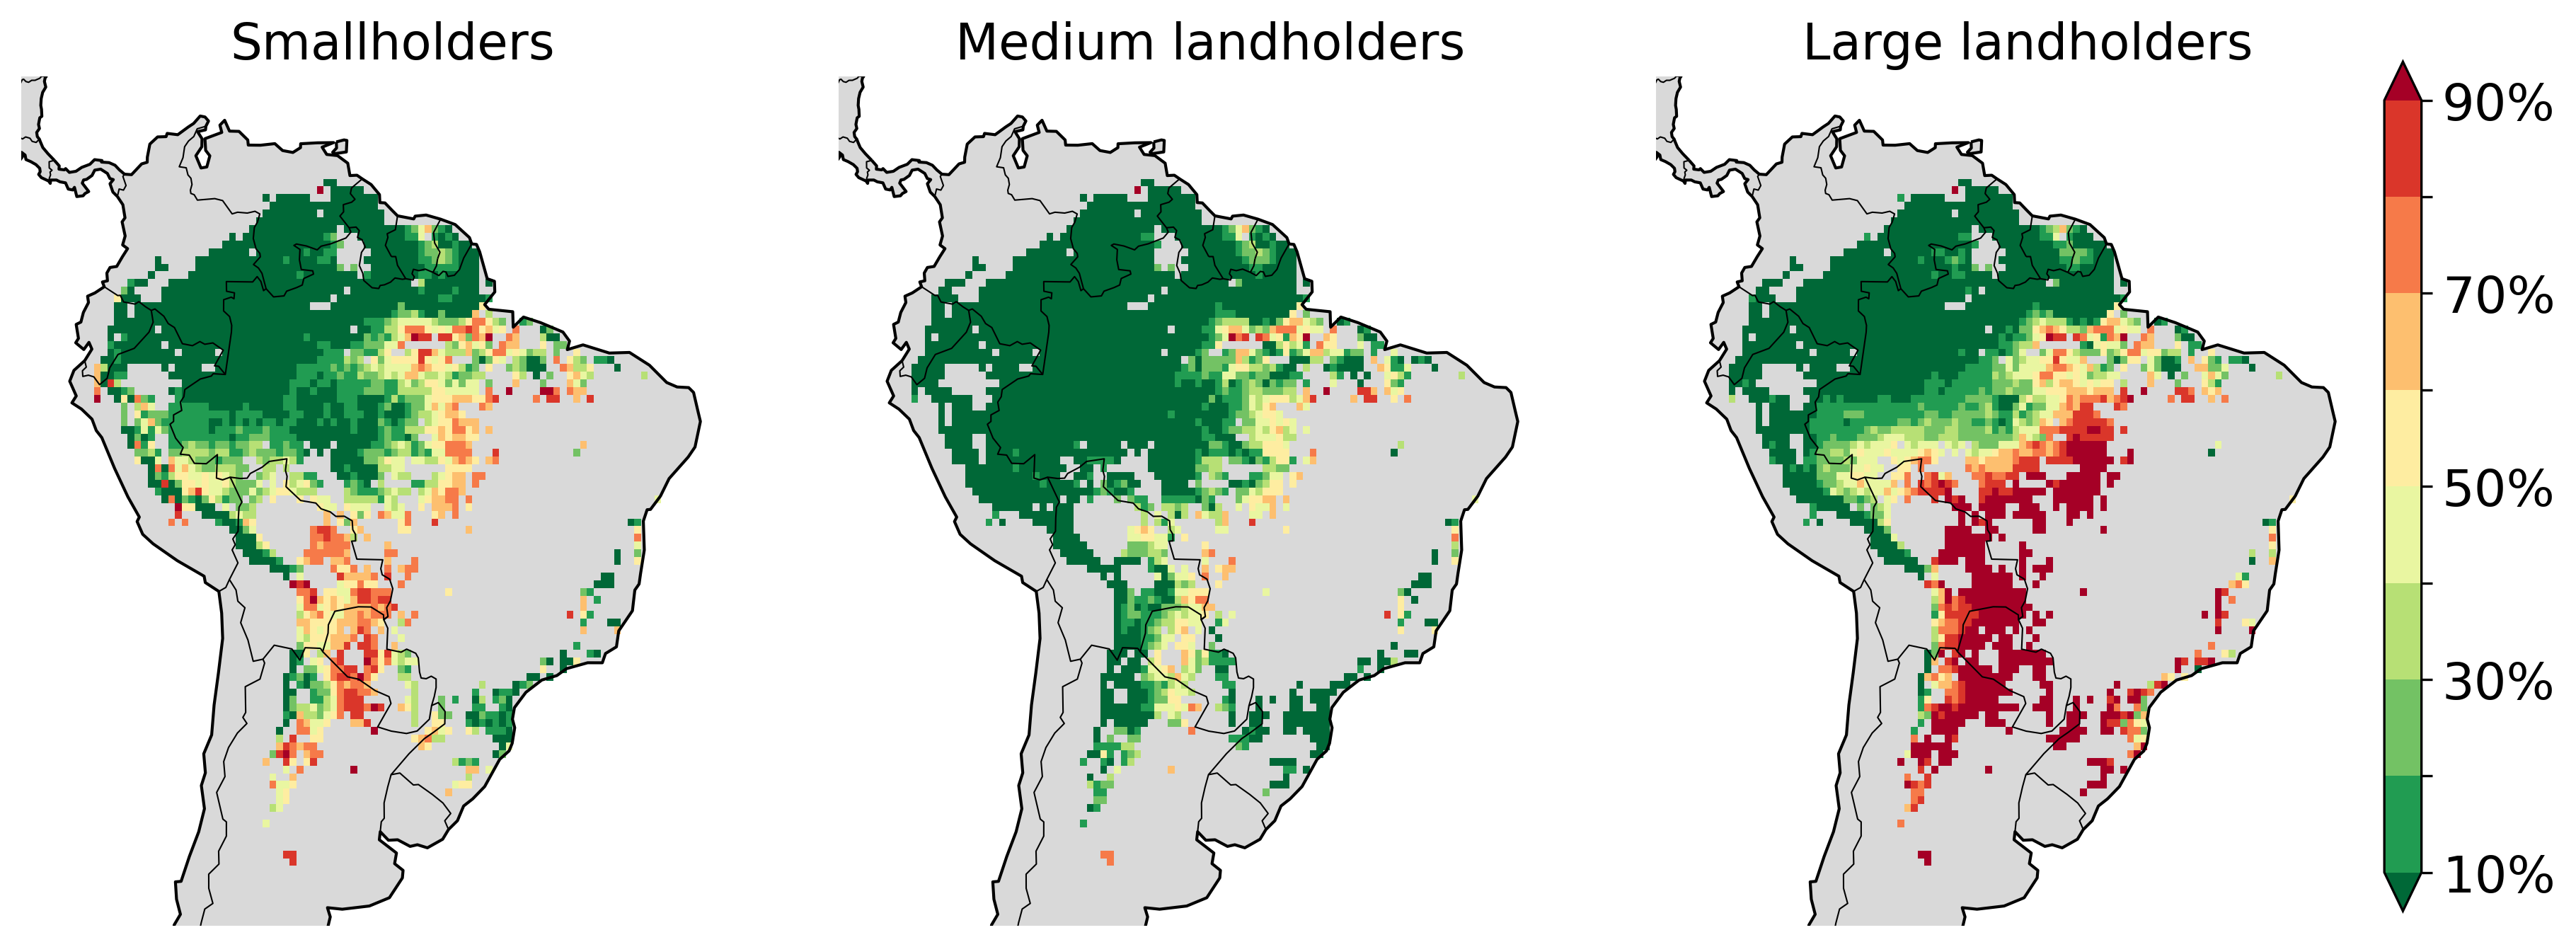

In [33]:

fig = plt.figure(figsize=(14,5), dpi = 300)
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'),
      plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]

im = ((Resilience.values-Small)/Resilience*100).plot(add_colorbar=False, ax = ax[0], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[0].set_title('Smallholders', fontsize = '17')

im = ((Resilience.values-Medium)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[1].set_title('Medium landholders', fontsize = '17')

im = ((Resilience.values-Large)/Resilience*100).plot(add_colorbar=False, ax = ax[2], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
axs = inset_axes(ax[2], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,2), bbox_transform=ax[2].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', ' ', '30%', ' ', '50%', ' ', '70%', ' ', '90%'])
ax[2].set_title('Large landholders', fontsize = '17')


for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')

#fig.suptitle('Influence over forest resilience', fontsize = 20)
plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0.1)
#plt.tight_layout()
plt.show()

In [36]:
Large = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Largeholders_'+Landuse_map+'_80decrease.nc').Resilience
Medium = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Mediumholders_'+Landuse_map+'_80decrease.nc').Resilience
Small = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Smallholders_'+Landuse_map+'_80decrease.nc').Resilience

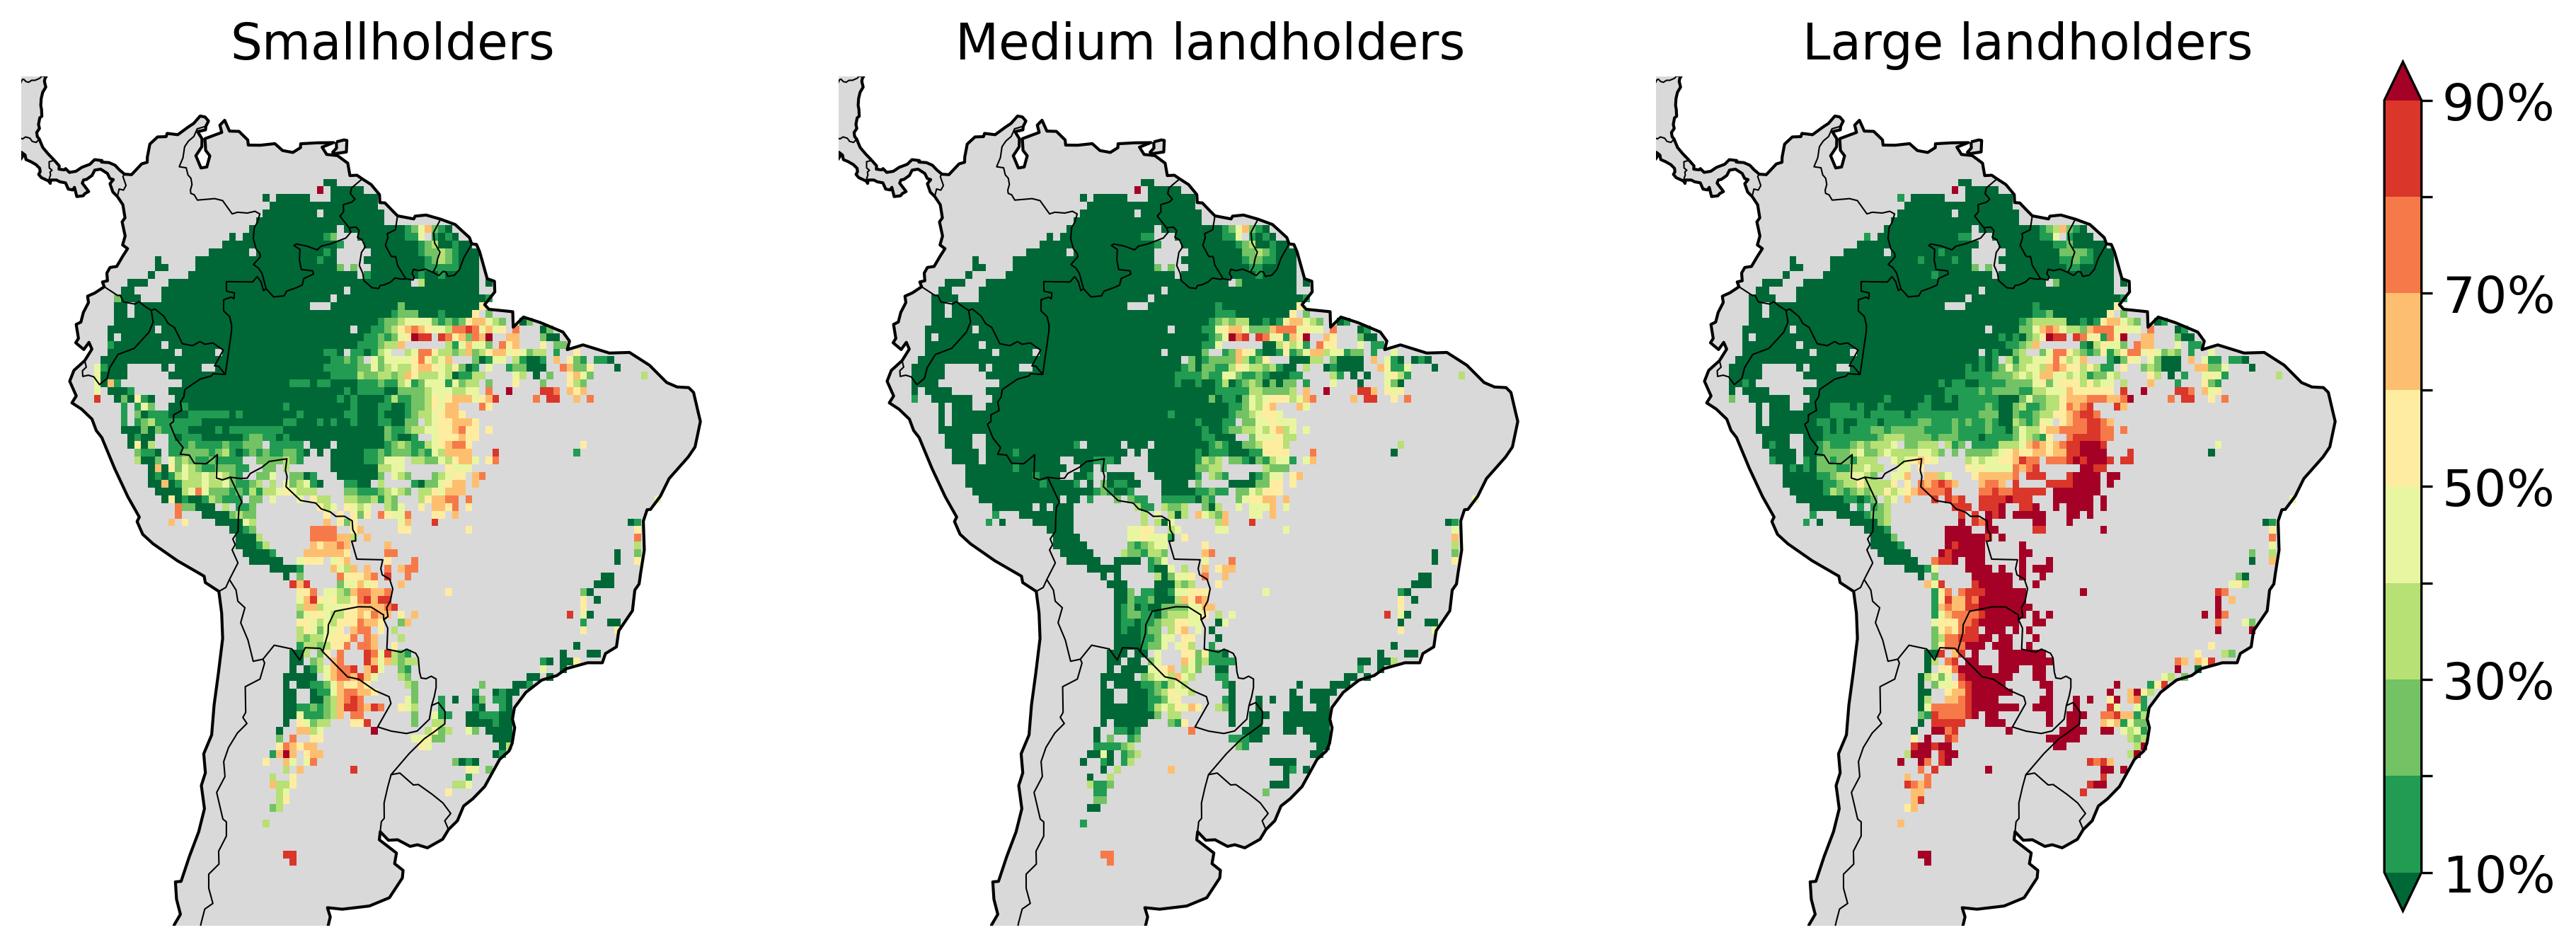

In [37]:

fig = plt.figure(figsize=(14,5), dpi = 300)
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'),
      plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]

im = ((Resilience.values-Small)/Resilience*100).plot(add_colorbar=False, ax = ax[0], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[0].set_title('Smallholders', fontsize = '17')

im = ((Resilience.values-Medium)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[1].set_title('Medium landholders', fontsize = '17')

im = ((Resilience.values-Large)/Resilience*100).plot(add_colorbar=False, ax = ax[2], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
axs = inset_axes(ax[2], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,2), bbox_transform=ax[2].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', ' ', '30%', ' ', '50%', ' ', '70%', ' ', '90%'])
ax[2].set_title('Large landholders', fontsize = '17')


for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')

#fig.suptitle('Influence over forest resilience', fontsize = 20)
plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0.1)
#plt.tight_layout()
plt.show()

In [39]:
Large = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Largeholders_'+Landuse_map+'_50decrease.nc').Resilience
Medium = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Mediumholders_'+Landuse_map+'_50decrease.nc').Resilience
Small = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr_Smallholders_'+Landuse_map+'_50decrease.nc').Resilience

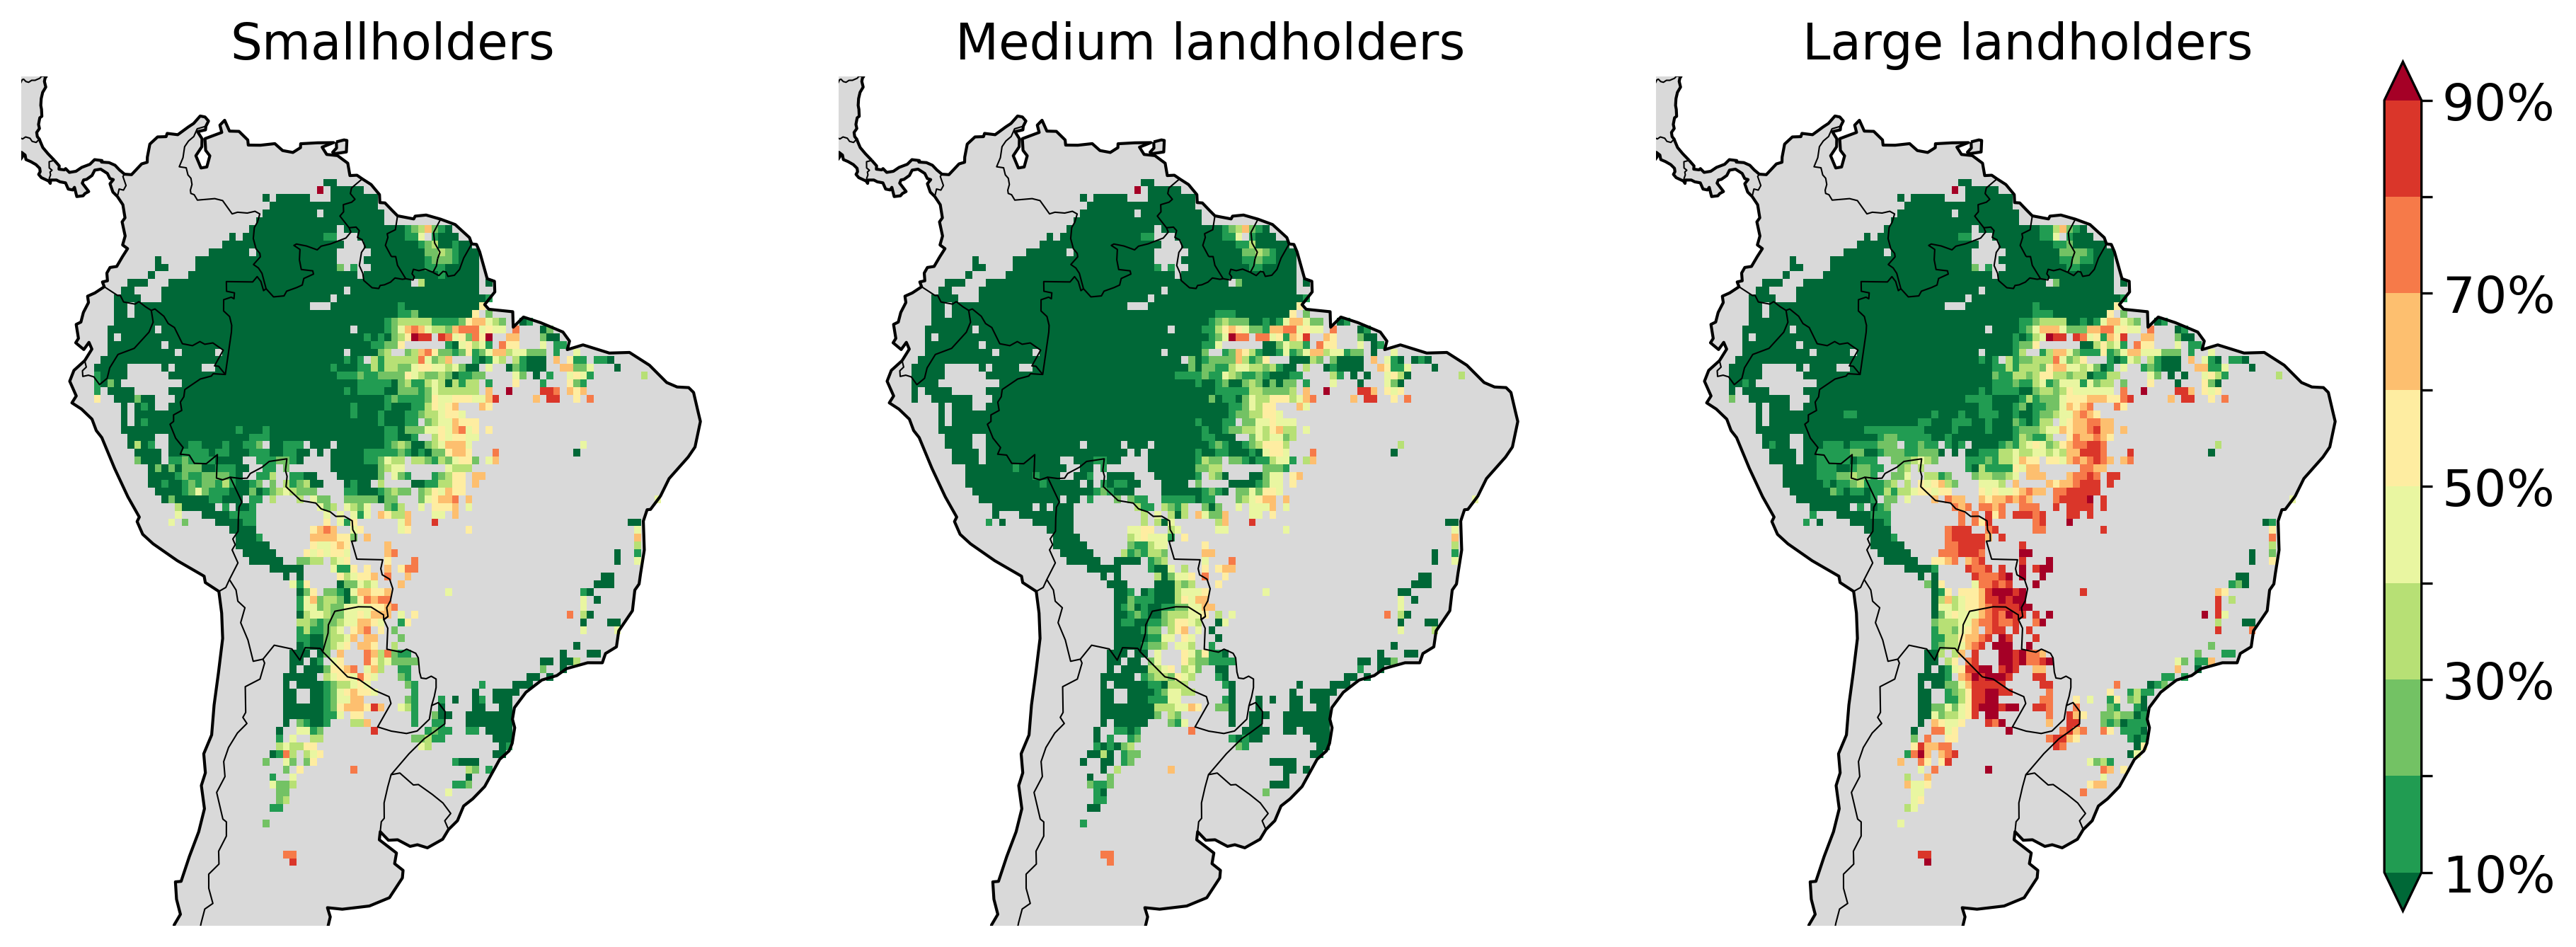

In [40]:

fig = plt.figure(figsize=(14,5), dpi = 300)
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'),
      plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]

im = ((Resilience.values-Small)/Resilience*100).plot(add_colorbar=False, ax = ax[0], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[0].set_title('Smallholders', fontsize = '17')

im = ((Resilience.values-Medium)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[1].set_title('Medium landholders', fontsize = '17')

im = ((Resilience.values-Large)/Resilience*100).plot(add_colorbar=False, ax = ax[2], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
axs = inset_axes(ax[2], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,2), bbox_transform=ax[2].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', ' ', '30%', ' ', '50%', ' ', '70%', ' ', '90%'])
ax[2].set_title('Large landholders', fontsize = '17')


for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')

#fig.suptitle('Influence over forest resilience', fontsize = 20)
plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0.1)
#plt.tight_layout()
plt.show()

In [41]:
Resilience = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P.nc').Resilience

In [42]:
Large = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P_Largeholders_'+Landuse_map+'.nc').Resilience
Medium = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P_Mediumholders_'+Landuse_map+'.nc').Resilience
Small = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P_Smallholders_'+Landuse_map+'.nc').Resilience

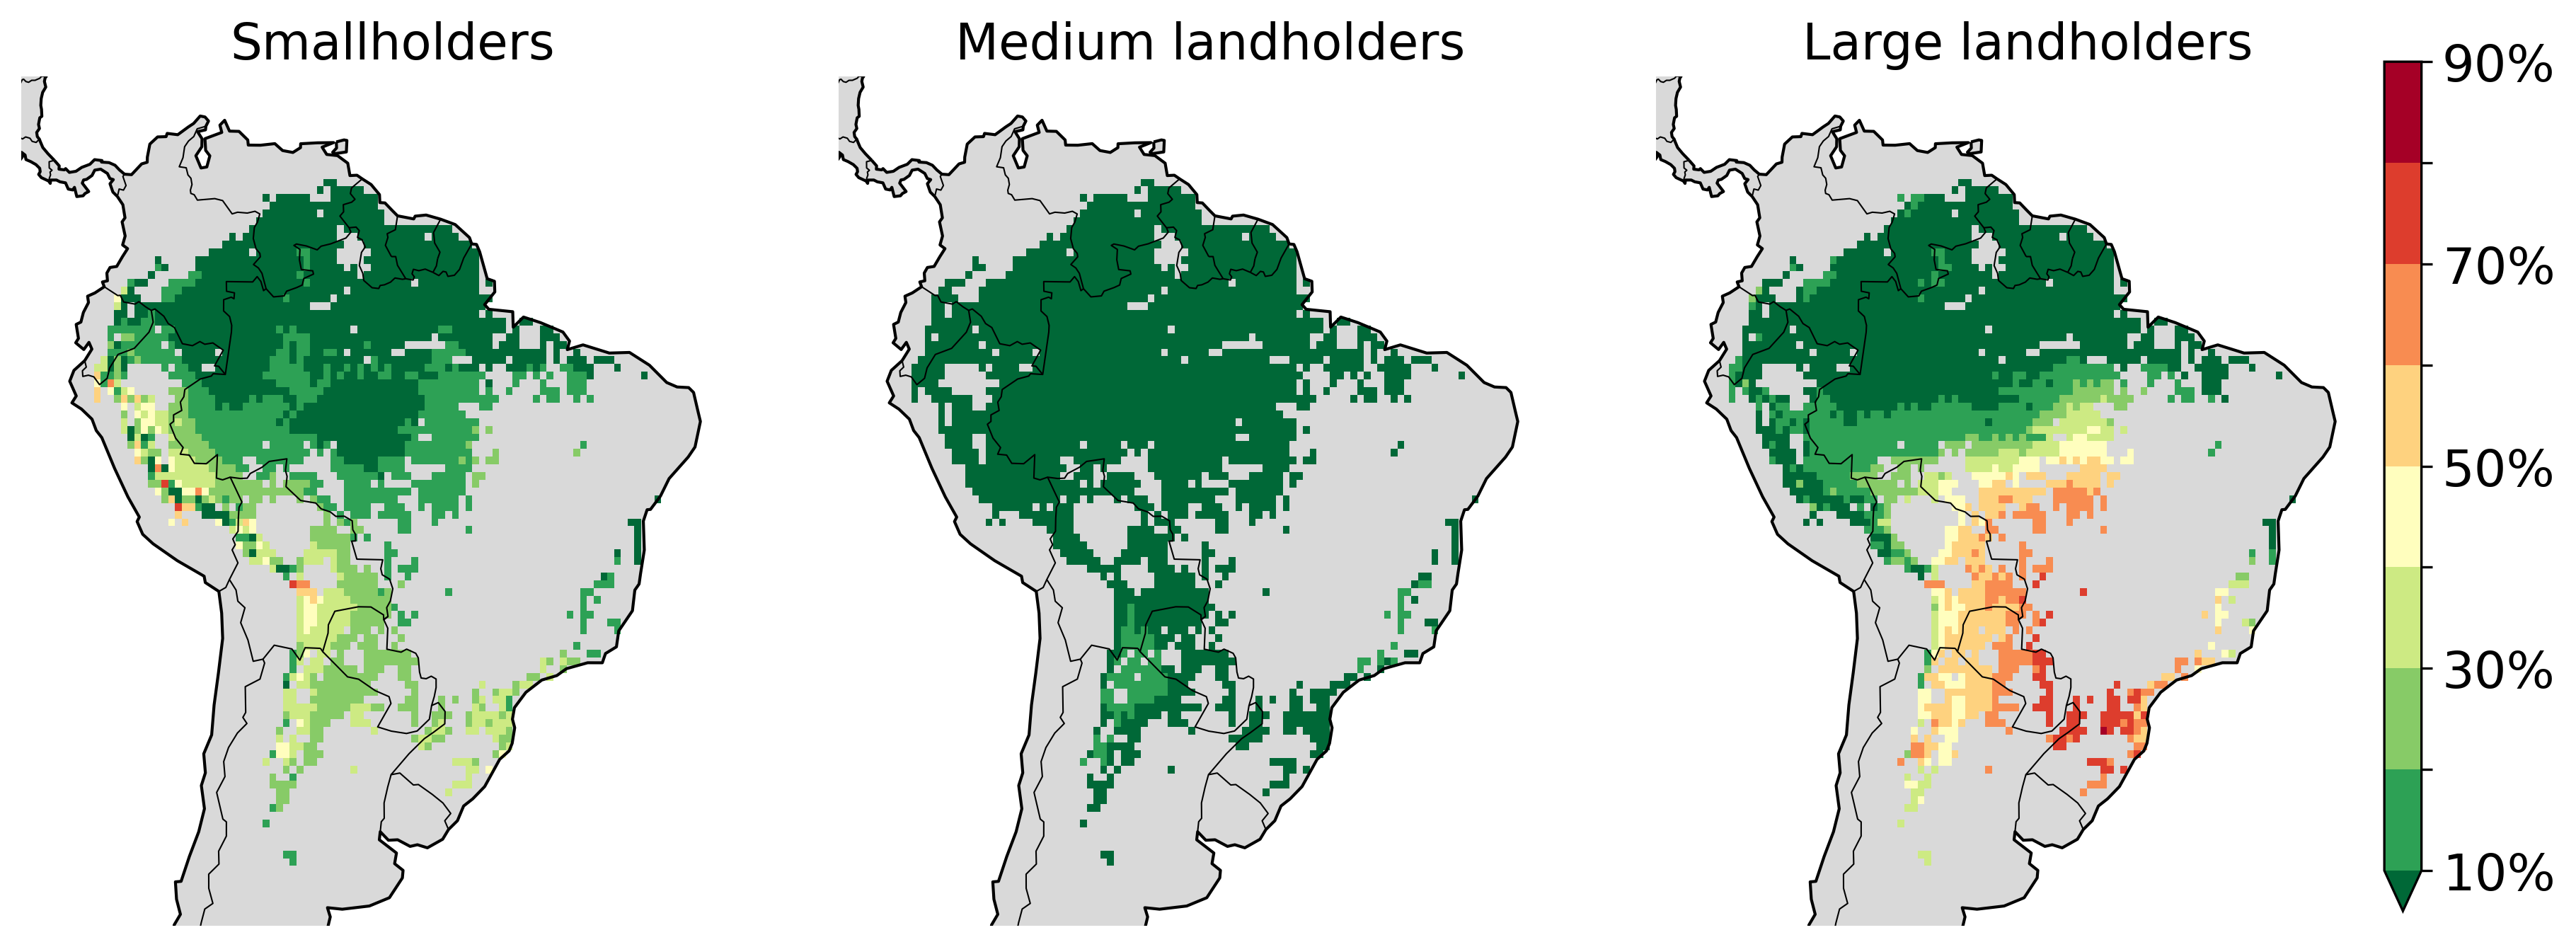

In [43]:

fig = plt.figure(figsize=(14,5), dpi = 300)
ax = [plt.subplot(131,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(132,projection=ccrs.PlateCarree(), aspect='auto'),
      plt.subplot(133,projection=ccrs.PlateCarree(), aspect='auto')]

im = ((Resilience.values-Small)/Resilience*100).plot(add_colorbar=False, ax = ax[0], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[0].set_title('Smallholders', fontsize = '17')

im = ((Resilience.values-Medium)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
ax[1].set_title('Medium landholders', fontsize = '17')

im = ((Resilience.values-Large)/Resilience*100).plot(add_colorbar=False, ax = ax[2], vmin = 10, vmax = 90, cmap = 'RdYlGn_r', levels = 9, extend= None)
axs = inset_axes(ax[2], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,2), bbox_transform=ax[2].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', ' ', '30%', ' ', '50%', ' ', '70%', ' ', '90%'])
ax[2].set_title('Large landholders', fontsize = '17')


for i in range(3):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')

#fig.suptitle('Influence over forest resilience', fontsize = 20)
plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0.1)
#plt.tight_layout()
plt.show()

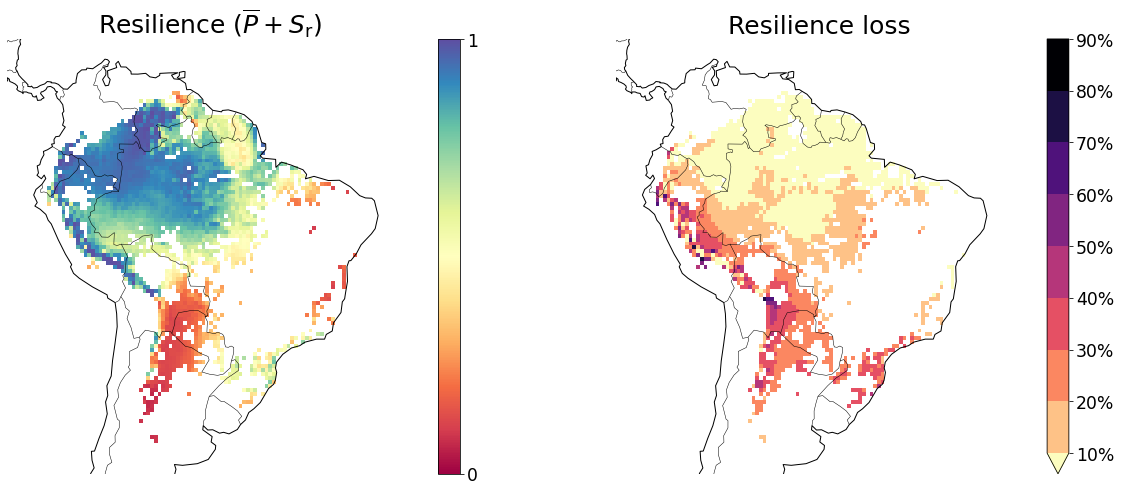

In [37]:
#Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = ((Resilience.values-Small)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'magma_r', levels = 9, extend= None)
cb = plt.colorbar(im, pad=0.05)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%', '90%']) 

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience loss', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()


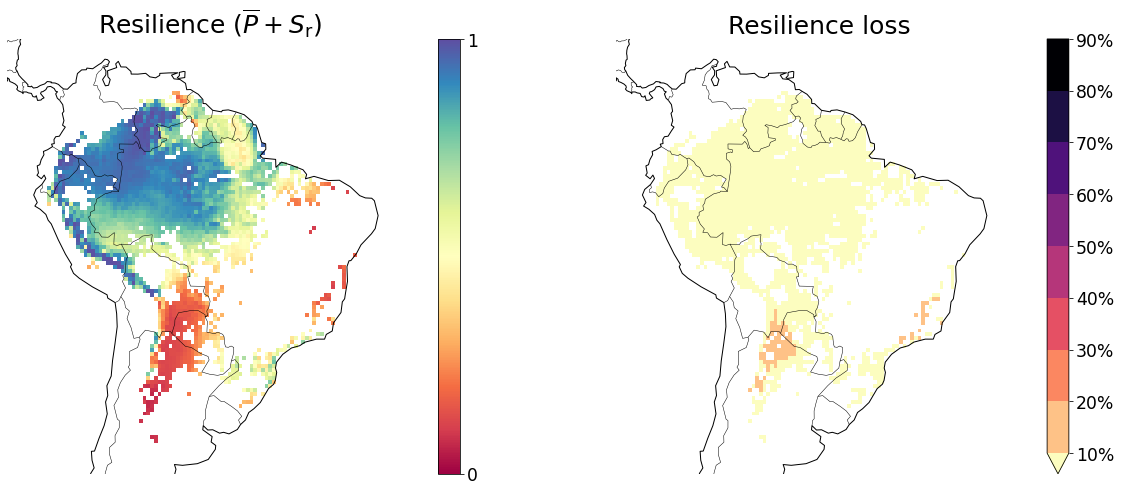

In [38]:
#Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = ((Resilience.values-Medium)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'magma_r', levels = 9, extend= None)
cb = plt.colorbar(im, pad=0.05)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%', '90%']) 


#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience loss', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()


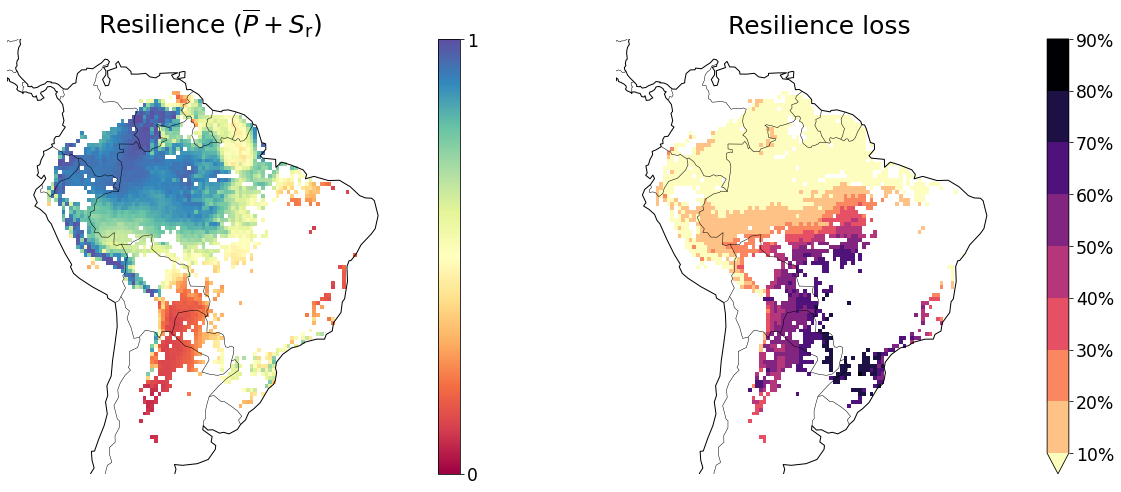

In [39]:
#Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})

plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = ((Resilience.values-Large)/Resilience*100).plot(add_colorbar=False, ax = ax[1], vmin = 10, vmax = 90, cmap = 'magma_r', levels = 9, extend= None)
cb = plt.colorbar(im, pad=0.05)
cb.ax.tick_params(labelsize='xx-large')
cb.ax.set_yticklabels(['10%', '20%', '30%', '40%', '50%', '60%', '70%', '80%', '90%']) 


#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience loss', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
plt.show()

In [6]:
B_MF_Small = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Smallholders_Mapbiomas.nc').Evap_footprint.sum(axis = 0)
B_MF_Medium = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Mediumholders_Mapbiomas.nc').Evap_footprint.sum(axis = 0)
B_MF_Large = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Largeholders_Mapbiomas.nc').Evap_footprint.sum(axis = 0)

B_MF_Small_F = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Smallholders_Mapbiomas_Forest_only.nc').Evap_footprint.sum(axis = 0)
B_MF_Medium_F = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Mediumholders_Mapbiomas_Forest_only.nc').Evap_footprint.sum(axis = 0)
B_MF_Large_F = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Backtracking_Largeholders_Mapbiomas_Forest_only.nc').Evap_footprint.sum(axis = 0)

Text(0.5, 1.0, 'Large landholders \nforest')

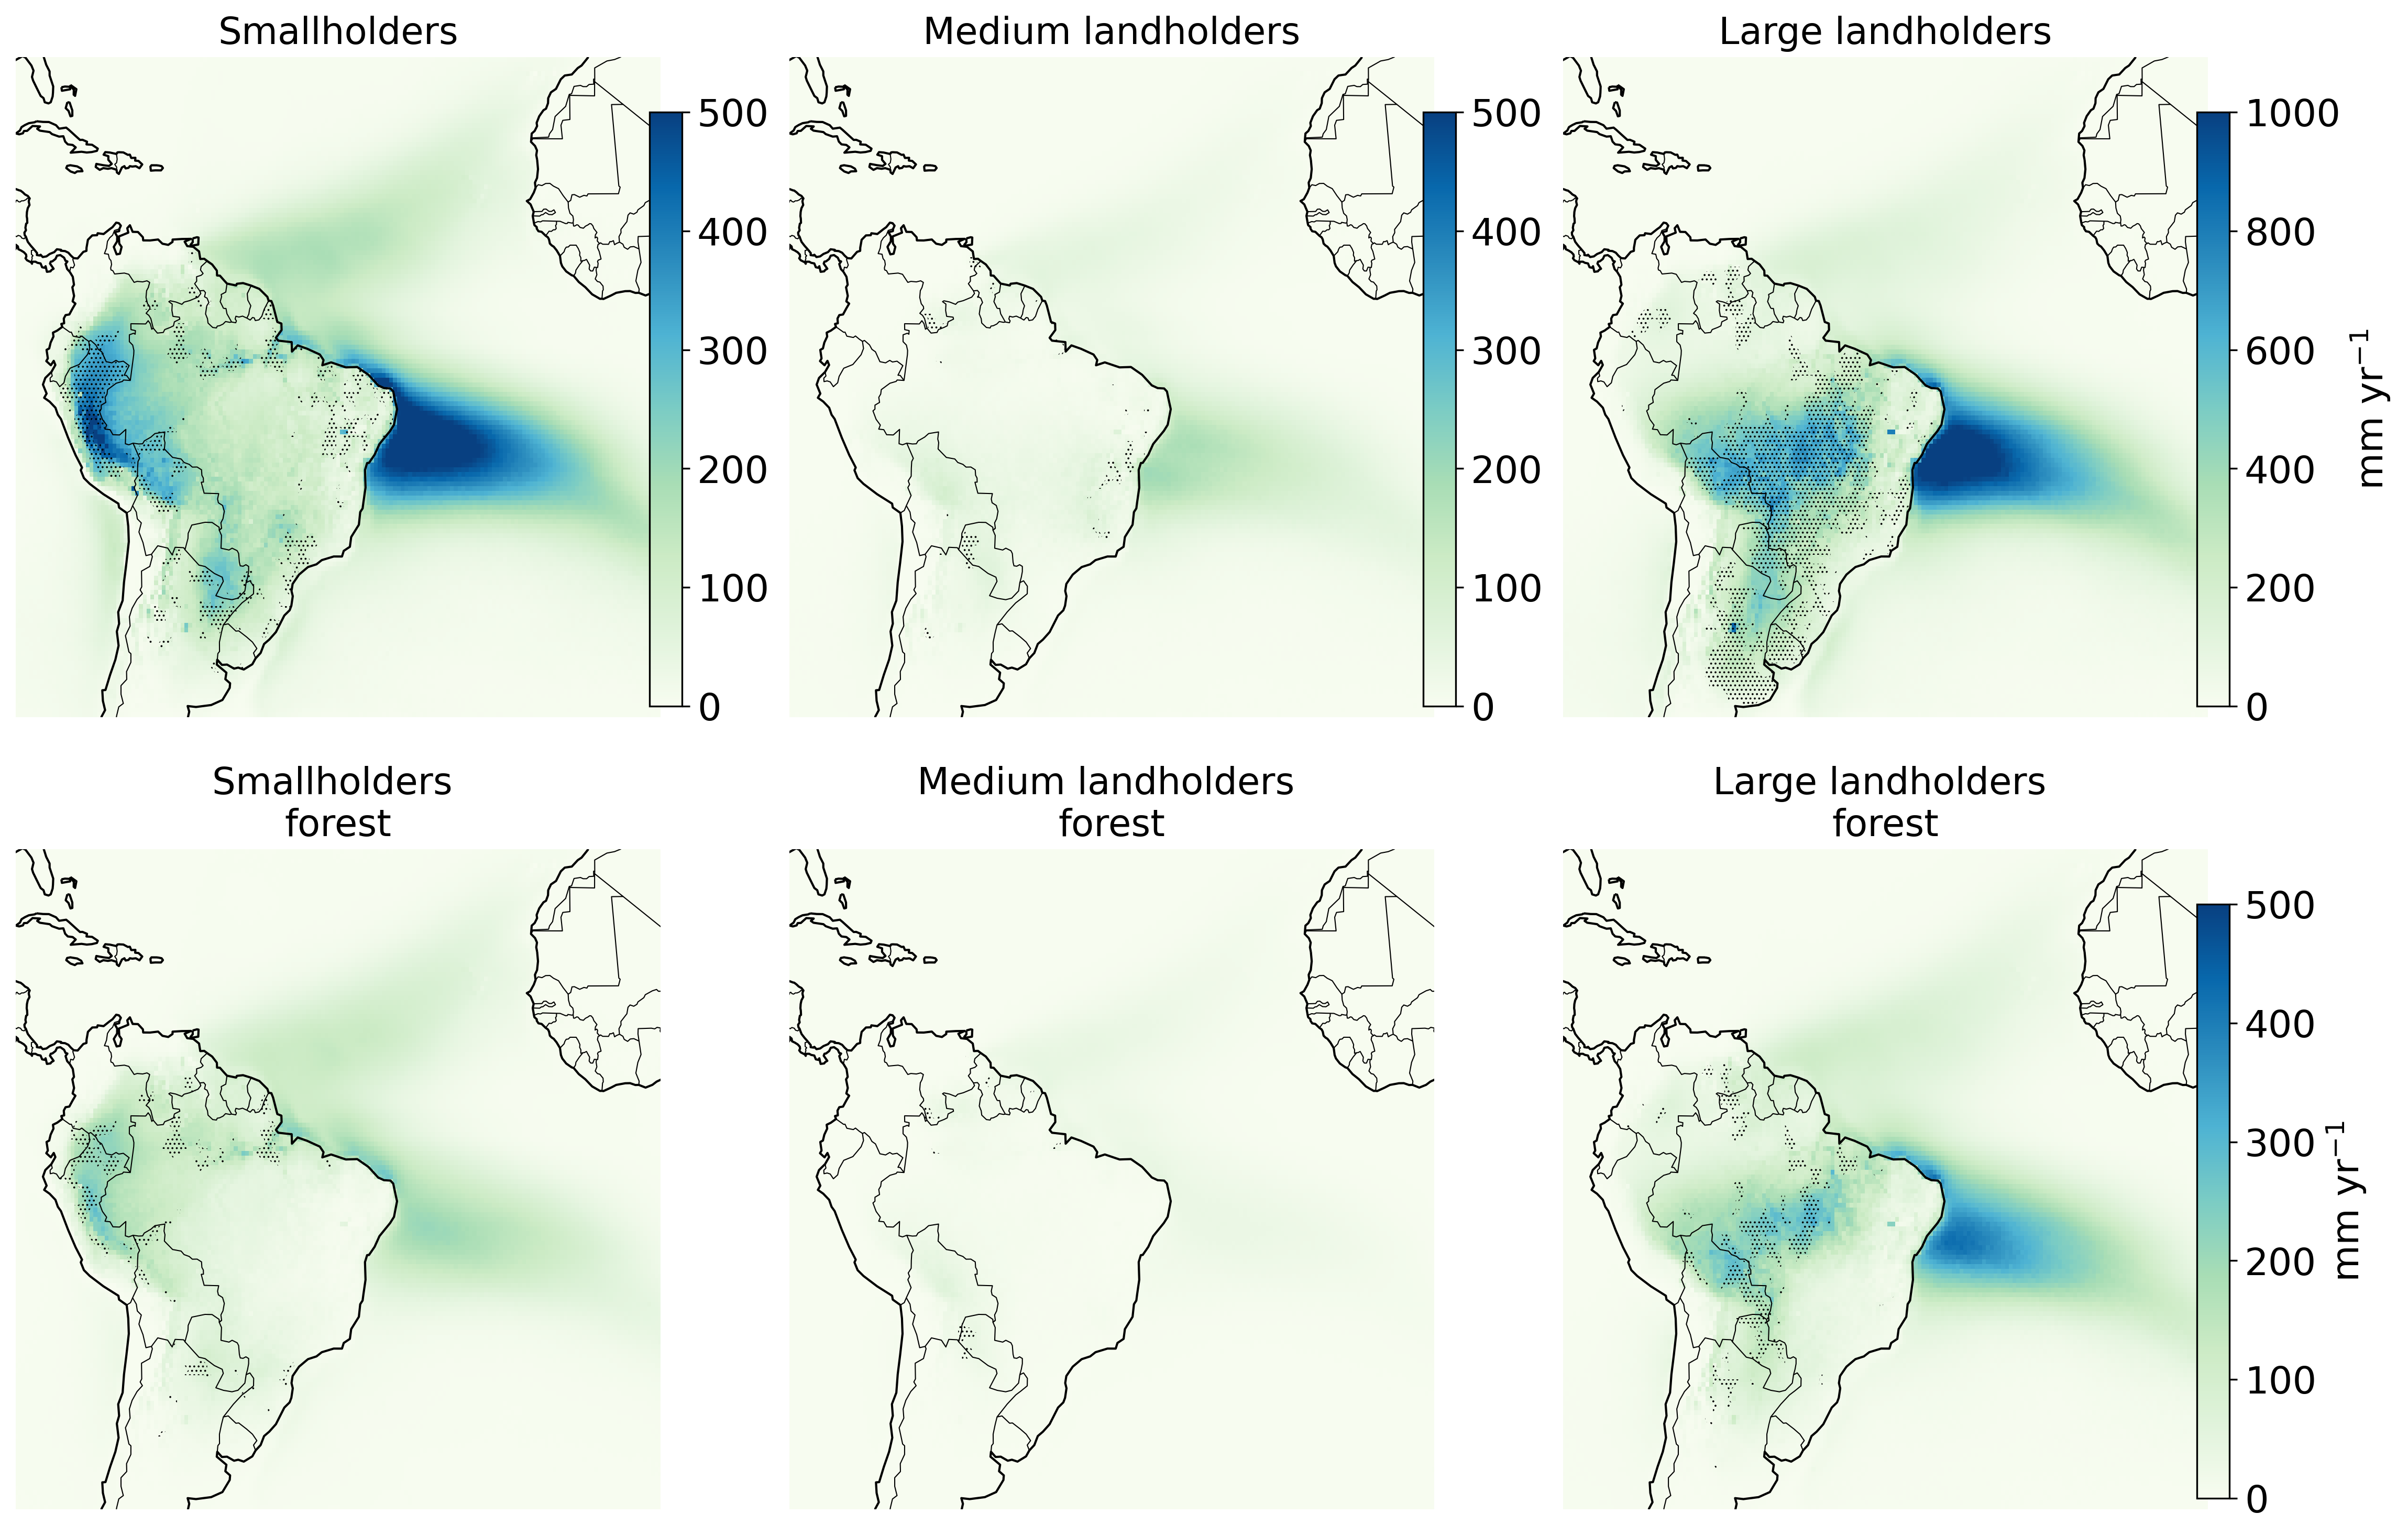

In [13]:
import cartopy as cart

plt.rcParams['hatch.linewidth'] = 0.5

fig = plt.figure(figsize=(18,12), dpi = 300)
ax = [plt.subplot(231,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(232,projection=ccrs.PlateCarree(), aspect='auto'),
      plt.subplot(233,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(234,projection=ccrs.PlateCarree(), aspect='auto'), 
      plt.subplot(235,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(236,projection=ccrs.PlateCarree(), aspect='auto')]

for i in range(6):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    #ax[i].set_xlim(-85,-30)
    #ax[i].set_ylim(-40, 15)
    ax[i].set_xlim(-85,0)
    ax[i].set_ylim(-40, 30)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
    
    
Stakeholder_int = 1
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = B_MF_Small.plot(add_colorbar=False, ax = ax[0], cmap = 'GnBu', vmin = 0, vmax = 500)
axs = inset_axes(ax[0], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[0].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].contourf(Stakeholder.where(Stakeholder == 1).x.values, Stakeholder.where(Stakeholder == 1).y.values, 
             Stakeholder.where(Stakeholder == 1).values, hatches=['......'], colors='none')
ax[0].set_title('Smallholders', fontsize = '17')

Stakeholder_int = 2
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = B_MF_Medium.plot(add_colorbar=False, ax = ax[1], cmap = 'GnBu', vmin = 0, vmax = 500)
axs = inset_axes(ax[1], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[1].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[2], s=1, marker=".", c='k')
ax[1].contourf(Stakeholder.where(Stakeholder == 2).x.values, Stakeholder.where(Stakeholder == 2).y.values, 
             Stakeholder.where(Stakeholder == 2).values, hatches=['......'], colors='none')
ax[1].set_title('Medium landholders', fontsize = '17')


Stakeholder_int = 3
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = B_MF_Large.plot(add_colorbar=False, ax = ax[2], cmap = 'GnBu', vmin = 0, vmax = 1000)
axs = inset_axes(ax[2], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[2].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.set_label(label = r'mm ${\mathrm{yr}^{-1}}$', size='xx-large')
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[4], s=1, marker=".", c='black')
ax[2].contourf(Stakeholder.where(Stakeholder == 3).x.values, Stakeholder.where(Stakeholder == 3).y.values, 
             Stakeholder.where(Stakeholder == 3).values, hatches=['......'], colors='none')

ax[2].set_title('Large landholders', fontsize = '17')

#######################################################################

Stakeholder_int = 1
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])

Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = B_MF_Small_F.plot(add_colorbar=False, ax = ax[3], cmap = 'GnBu', vmin = 0, vmax = 500)

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
y_forest = LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)).where((Stakeholder.values == 1) & 
                        (LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)) == 1))
ax[3].contourf(y_forest.x.values, y_forest.y.values, y_forest.values, hatches=['......'], colors='None')
ax[3].set_title('Smallholders \nforest', fontsize = '17')

#ax[0].set_title('Precipitation originating from \nupwind sources', fontsize = '20')


Stakeholder_int = 2
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = B_MF_Medium_F.plot(add_colorbar=False, ax = ax[4], cmap = 'GnBu', vmin = 0, vmax = 500)

#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[2], s=1, marker=".", c='k')
y_forest = LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)).where((Stakeholder.values == 2) & 
                        (LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)) == 1))
ax[4].contourf(y_forest.x.values, y_forest.y.values, y_forest.values, hatches=['......'], colors='None')
ax[4].set_title('Medium landholders \nforest', fontsize = '17')


Stakeholder_int = 3
Lat = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[0]:
        Lat.append(data.y.values[lat])
Lon = []
for lat in np.argwhere(data[0].values == Stakeholder_int).transpose()[1]:
        Lon.append(data.x.values[lat])
Screened_data = pd.DataFrame({'Lat': np.array(Lat), 'Lon': np.array(Lon)})
im = B_MF_Large_F.plot(add_colorbar=False, ax = ax[5], cmap = 'GnBu', vmin = 0, vmax = 500)
axs = inset_axes(ax[5], width="5%", height="50%", loc='lower right', bbox_to_anchor=(0.05,0,1,1.8), bbox_transform=ax[5].transAxes)
cb = plt.colorbar(im, pad=0.05, cax = axs)
cb.set_label(label = r'mm ${\mathrm{yr}^{-1}}$', size='xx-large')
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[4], s=1, marker=".", c='black')
y_forest = LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)).where((Stakeholder.values == 3) & 
                        (LU_Mapbiomas.sel(y = slice(-39.25, 10.25), x = slice(280, 330)) == 1))
ax[5].contourf(y_forest.x.values, y_forest.y.values, y_forest.values, hatches=['......'], colors='None')
ax[5].set_title('Large landholders \nforest', fontsize = '17')

#plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.1, hspace=0.1)
#plt.show()
#plt.savefig('/home/chandra/data/Paper4/Output/Moisture_flows_assessments/Moisture_forwardtracking.svg', dpi = 10)

In [5]:
Resilience = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P+Sr.nc').Resilience
Resilience_P = xr.open_dataset('/home/chandra/data/Paper4/Output/Resilience_assessments/Resilience_P.nc').Resilience

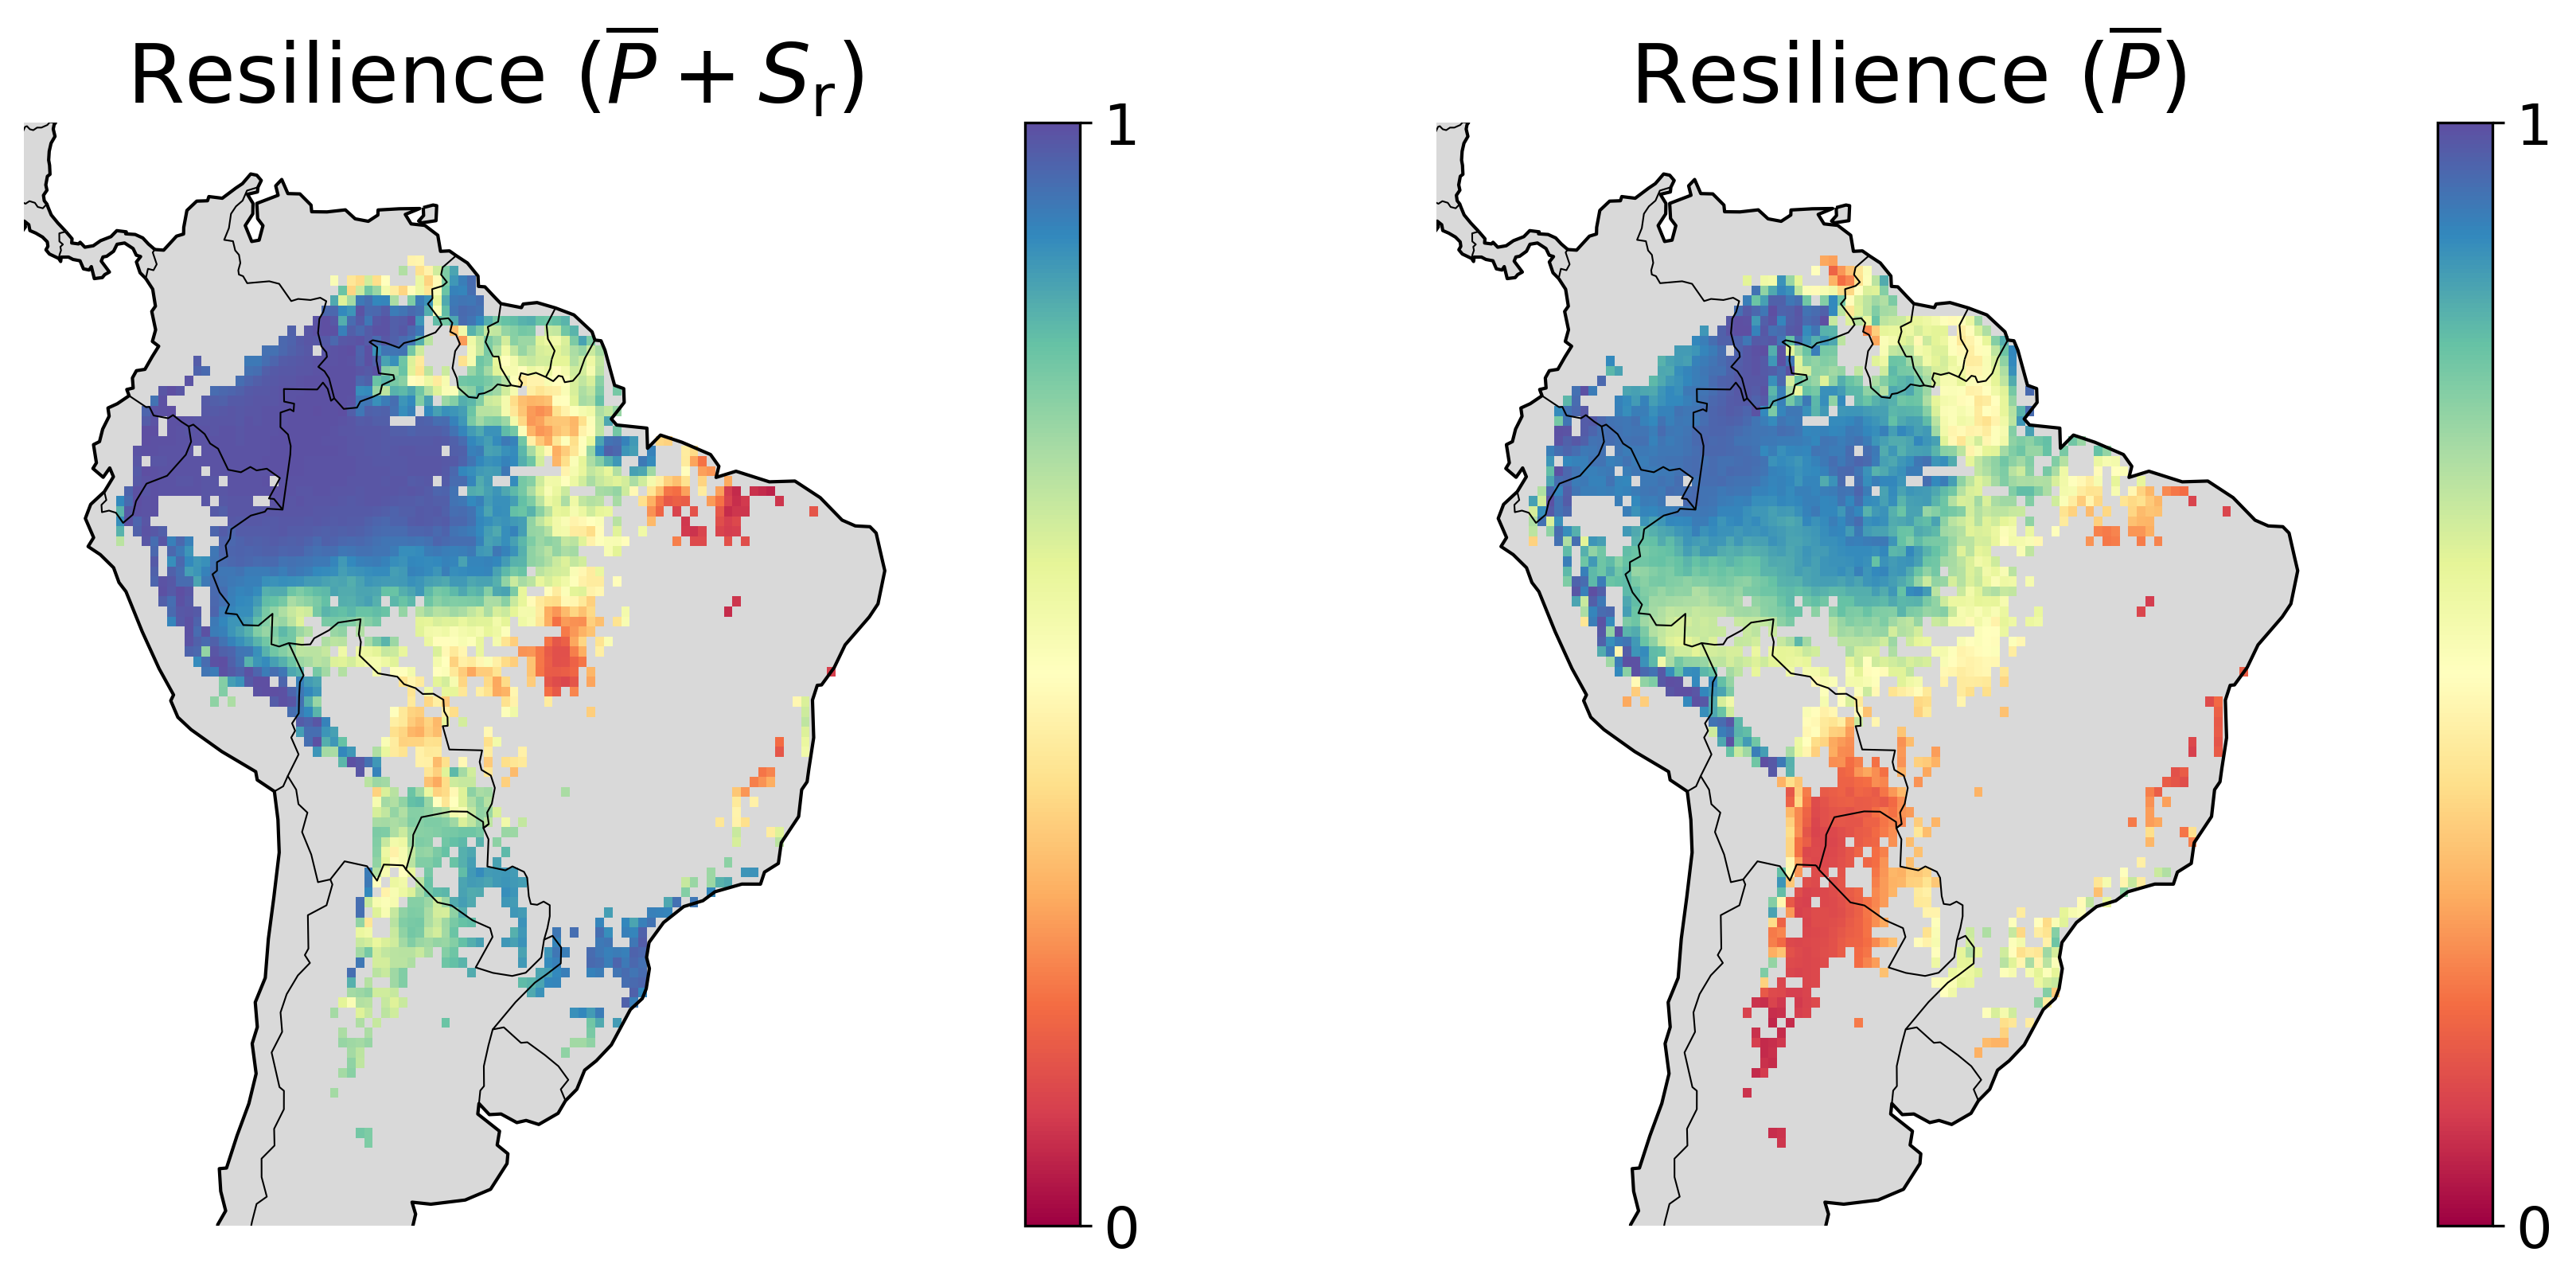

In [13]:
plt.rcParams['hatch.linewidth'] = 0.25   

fig = plt.figure(figsize=(14,6), dpi = 300)
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]

im = Resilience.plot(add_colorbar=False, ax = ax[0], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[0])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[0].set_title('Resilience ($\overline{P}+S_{\mathrm{r}}$)', fontsize = '25')

im = Resilience_P.plot(add_colorbar=False, ax = ax[1], vmin = 0, vmax = 1, cmap = 'Spectral',)
cb = plt.colorbar(im, pad=0.05, ticks = [0,1], ax = ax[1])
cb.ax.tick_params(labelsize='xx-large')
#Screened_data.plot.scatter(x = 'Lon', y = 'Lat', ax = ax[0], s=1, marker=".", c='k')
ax[1].set_title('Resilience ($\overline{P}$)', fontsize = '25')


for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    ax[i].add_feature(cart.feature.LAND, zorder=-100, facecolor='#d9d9d9')
plt.show()

NameError: name 'img' is not defined

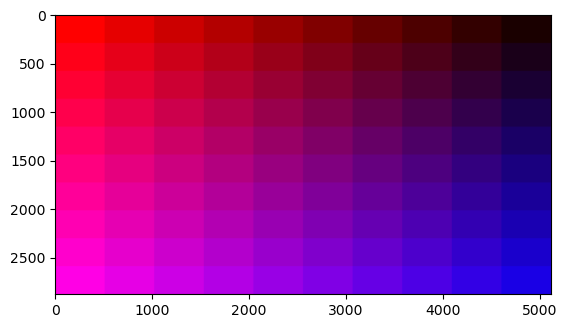

In [1]:
# ---- snipped code already in the question -----
import numpy as np
import matplotlib.pyplot as plt

#  fake a choropleth in a dirty, fast way
height, width = 2880, 5120
choropleth = np.empty((height, width, 3,), dtype=np.uint8)
CHUNKS = 10
x_size = width // CHUNKS
for x_step, x in enumerate(range(0, width, width // CHUNKS)):
    y_size = height // CHUNKS
    for y_step, y in enumerate(range(0, height, height // CHUNKS)):
        choropleth[y: y+y_size, x: x+x_size] = (255-x_step*255//CHUNKS,
                                                0, y_step*255//CHUNKS)
plt.figure("Fake Choropleth")
plt.imshow(choropleth)

# Option 1: play with alpha only
outimage = np.empty((height, width, 4,), dtype=np.uint8)  # RGBA image
outimage[:, :, 3] = img  # Set alpha channel
outimage[:, :, :3] = choropleth  # Set color
plt.figure("Alpha filter only")
plt.imshow(outimage)

# Option 2: clear the empty points
outimage[img == 0, :3] = 0  # White. use 0 for black
plt.figure("Points erased")
plt.imshow(outimage[:,:,:3])  # change to 'outimage' to see the image with alpha